# Le réseau ferré français vu comme un graphe

*Projet du cours* Metabolic networks / Graph analysis *(C. Frainay, F. Jourdan, INRAE Toxalim).* Les méthodes d'analyse de graphes du cours sont appliquées à un autre réseau réel, le réseau ferré national (RFN), puis comparées à l'Allemagne.

**Démarche du cours**, appliquée à chaque question :
1. définir ce que représentent les nœuds et les arêtes, et prétraiter le graphe (*« careful relevance assessment of nodes and edges, followed by graph pre-processing is always required »*) ;
2. choisir une métrique du cours (centralité, chemins, composantes) ;
3. choisir la visualisation qui répond à la question (*« one tailored visualization for each type of analysis »*).

Chaque question est traitée par **une figure**, suivie d'une **légende** qui en donne la lecture.

| Question | Notion du cours | Figure |
|---|---|---|
| Q1. Où sont les lignes à grande vitesse ? | attributs des arêtes | 1 |
| Q2. Où circulent les trains ? | graphe pondéré | 2 |
| Q3. Quelles villes sont proches de tout le réseau ? | closeness, farness | 3 |
| Q4. Où sont le centre et la périphérie ? | excentricité, rayon, diamètre | 4 |
| Q5. Quels sont les points névralgiques ? | betweenness des nœuds et des arêtes | 5 |
| Q6. Que se passe-t-il si on retire les villes les plus importantes ? | robustesse, points d'articulation | 6 |
| Q7. Les trajets de la promotion vers Rouen | plus court chemin pondéré, sous-graphe, vue schématique | 7 |
| Q8. Les régions sont-elles inégalement desservies ? | attributs des nœuds, graphe quotient | 8 |
| Q9. Quelles villes ne sont pas connectées ? | composantes connexes | 9 |
| Q10. Quelles gares sont les plus et les moins connectées ? | degré, distribution des degrés | 10 |
| Q11. Quel trajet passe obligatoirement par le plus de gares ? | plus court chemin non pondéré | 11 |
| Bonus. La France est-elle plus centralisée que l'Allemagne ? | métriques globales, modularité | 12 |

## 1. Données et construction du graphe

| Fichier brut | Source | Information retenue |
|---|---|---|
| `liste-des-gares.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/liste-des-gares/) | gares voyageurs : code UIC, nom, commune, département, ligne et point kilométrique (PK), coordonnées |
| `fichier-de-formes-des-voies-du-reseau-ferre-national.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/fichier-de-formes-des-voies-du-reseau-ferre-national/) | tracé de chaque tronçon : où les lignes se raccordent |
| `vitesse-maximale-nominale-sur-ligne.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/vitesse-maximale-nominale-sur-ligne/) | vitesse maximale par ligne : itinéraire le plus rapide d'un train |
| `lignes-par-statut.csv` | [SNCF Réseau](https://ressources.data.sncf.com/explore/dataset/lignes-par-statut/) | tracé et statut (exploitée, fermée…) : longueur le long de la voie, part sur LGV |
| `frequentation-gares.csv` | [SNCF Voyageurs](https://ressources.data.sncf.com/explore/dataset/frequentation-gares/) | voyageurs par gare en 2025 |
| `Export_OpenData_SNCF_GTFS_NewTripId.zip` | [SNCF Voyageurs, GTFS](https://ressources.data.sncf.com/explore/dataset/horaires-sncf/) | trains d'un mardi type (01/12/2026), TER, TGV, Intercités, sans Transilien ni RER |
| `latest.zip` | [gtfs.de](https://gtfs.de/en/feeds/de_full/) | trains allemands du même jour (bonus) |
| `communes.json`, `departements.json`, `regions.json` | [Etalab](https://github.com/etalab/decoupage-administratif) | code INSEE, population, département et région de chaque commune |

Les codes des lignes à grande vitesse sont les numéros RFN relevés dans les articles Wikipédia de chaque LGV, vérifiés par la longueur mesurée dans les données (par exemple 422 km pour la LGV Est, ligne 005000).

**Du CSV au graphe** (`preprocessing_datasets.py`) :
1. deux gares voisines sur une même ligne (ordonnées par PK) sont reliées ; les lignes sont raccordées entre elles aux bifurcations, repérées sur les tracés ;
2. chaque train du GTFS est projeté sur l'itinéraire le plus rapide entre ses arrêts, ce qui donne le nombre de trains par jour de chaque liaison ;
3. **hypothèse de modélisation** : toutes les gares d'une même commune INSEE forment **un seul nœud**, la ville (Paris : 31 gares, Lyon : 6) ; chaque liaison est mesurée le long du tracé.

Le script vérifie la table (doublons, boucles, liaisons orphelines, tracés incohérents) et écrit `villes.csv` (nœuds), `liaisons.csv` (arêtes) et le fichier Cytoscape.

**Le fichier Cytoscape** `data/genere/reseau_villes.cyjs` (format JSON de Cytoscape.js) est écrit directement à partir de ces deux tables :
- **un nœud par ligne de `villes.csv`** (2 597 villes), avec toutes ses colonnes comme attributs, plus `cle` (code INSEE) et `name` (nom de la ville) ; sa position est `x = lon × 100`, `y = −lat × 145`, si bien que le réseau s'ouvre comme une carte de France ;
- **une arête par ligne de `liaisons.csv`** (3 182 liaisons), avec toutes ses colonnes, plus `cle` = `source~target` et `interaction` = `rail`.

La clé `cle` permet d'ajouter à Cytoscape, comme nouvelles colonnes, les résultats calculés en Python.

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

DONNEES = Path("data/genere")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

villes = pd.read_csv(DONNEES / "villes.csv", dtype={"id": str, "departement": str, "region": str}).set_index("id")
liaisons = pd.read_csv(DONNEES / "liaisons.csv", dtype={"source": str, "target": str, "code_ligne": str})
print(f"{len(villes)} villes, {len(liaisons)} liaisons")
display(villes.head())
display(liaisons.head())

2597 villes, 3182 liaisons


,nom,departement,region,lon,lat,nb_gares,voyageurs_2025,population,nb_trains_jour,desservie,statut_desserte,reseau_principal
id,,,,,,,,,,,,
75056,Paris,75,11,2.356622,48.881053,31,793313445.0,2103778.0,957.0,NaN,inconnue (IDF),True
69123,Lyon,69,84,4.860201,45.760541,6,62858165.0,519127.0,874.0,True,desservie,True
91326,Juvisy-sur-Orge,91,11,2.383583,48.689257,1,41634282.0,19292.0,230.0,NaN,inconnue (IDF),True
93066,Saint-Denis,93,11,2.345561,48.935112,5,76118907.0,149077.0,522.0,NaN,inconnue (IDF),True
93005,Aulnay-sous-Bois,93,11,2.494081,48.932258,1,33692260.0,87599.0,58.0,NaN,inconnue (IDF),True


,source,target,code_ligne,type_ligne,lgv,part_lgv,nb_trains_jour,longueur_km,distance_km,distance_trace_km,vol_oiseau_km,detour
0,93031,MONTMAGNY|SEINE-SAINT-DENIS,"330000,960000",classique,False,NaN,37,0.241,0.241,NaN,0.117,NaN
1,69044,69250,782000,classique,False,0.0,87,0.836,0.823,0.836,0.823,1.016
2,13108,30032,"810000,830356",classique,False,0.0,28,0.840,0.839,0.840,0.804,1.045
3,59013,59602,268000,classique,False,NaN,0,0.873,0.873,NaN,0.868,NaN
4,92026,92062,973000,classique,False,0.0,0,0.971,0.896,0.971,0.896,1.084


**Colonnes de `liaisons.csv`** : `type_ligne` (LGV ou classique, LGV si plus de 50 % du tracé est sur LGV), `part_lgv`, `nb_trains_jour` (deux sens), `longueur_km` (le long du tracé, sinon par points kilométriques : **c'est le poids des arêtes**), `distance_km` (points kilométriques), `distance_trace_km` (tracé), `vol_oiseau_km`, `detour` (tracé / vol d'oiseau).

**Colonnes de `villes.csv`** : `id` (code INSEE), `nom`, `departement`, `region`, `lon`, `lat`, `nb_gares`, `voyageurs_2025`, `population`, `nb_trains_jour`, `statut_desserte` (desservie, non desservie, ou inconnue en Île-de-France faute de Transilien dans le GTFS), `reseau_principal`.

In [2]:
# Vérifications avant toute analyse : la table doit être propre
assert not villes.index.duplicated().any(), "ville en double"
assert not liaisons.duplicated(["source", "target"]).any(), "liaison en double"
assert (liaisons["source"] != liaisons["target"]).all(), "boucle"
assert liaisons["source"].isin(villes.index).all() and liaisons["target"].isin(villes.index).all(), "liaison orpheline"
assert (liaisons["longueur_km"] > 0).all(), "longueur nulle"
print("Tracé / points kilométriques, rapport médian :",
      round((liaisons.distance_trace_km / liaisons.distance_km).median(), 3))

Tracé / points kilométriques, rapport médian : 1.013


## 2. Le graphe et les outils de dessin

- **Graphe** non orienté et pondéré : $G = (V, E)$, $V$ = villes, $E$ = liaisons, poids = `longueur_km`.
- Les métriques de distance (closeness, excentricité) exigent un graphe **connexe** : on les calcule sur la plus grande composante connexe $P$ (le réseau principal).
- Les cartes placent chaque ville à ses coordonnées : pour un réseau de transport la géographie a un sens, contrairement aux cartes de métabolisme (*« the map is not the territory »*).

In [3]:
G = nx.from_pandas_edgelist(liaisons, "source", "target", edge_attr=True)
G.add_nodes_from(villes.index)
P = G.subgraph(max(nx.connected_components(G), key=len)).copy()
POIDS = "longueur_km"
print(f"G : {G.number_of_nodes()} nœuds, {G.number_of_edges()} arêtes, "
      f"{nx.number_connected_components(G)} composantes ; réseau principal P : {P.number_of_nodes()} nœuds")

BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#c3c2b7"
BLEUS = LinearSegmentedColormap.from_list("bleus", ["#cde2fb", BLEU, "#0d366b"])  # clair = faible, foncé = fort
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pos = {v: (villes.lon[v], villes.lat[v]) for v in villes.index}


def tracer_liaisons(ax, aretes, couleur=GRIS, epaisseur=0.4):
    """Dessine les liaisons (liste de couples de villes) comme des segments."""
    ax.add_collection(LineCollection([(pos[a], pos[b]) for a, b in aretes], colors=couleur, linewidths=epaisseur))
    ax.autoscale()


def tracer_villes(ax, valeurs, legende, taille=6):
    """Villes colorées selon `valeurs` (une Series indexée par ville), valeurs fortes au-dessus."""
    v = valeurs.sort_values()
    if isinstance(taille, pd.Series):
        taille = taille[v.index]
    points = ax.scatter(villes.lon[v.index], villes.lat[v.index], c=v, cmap=BLEUS, s=taille, zorder=2)
    plt.colorbar(points, ax=ax, shrink=0.6, label=legende)


def nommer(ax, ids, etoile=False):
    for v in ids:
        if etoile:
            ax.scatter(villes.lon[v], villes.lat[v], marker="*", s=250, c="white", edgecolors="black", zorder=3)
        ax.annotate(villes.nom[v], pos[v], xytext=(5, 3), textcoords="offset points", fontsize=8)


def carte(ax, titre):
    ax.set_title(titre)
    ax.set_aspect(1.45)
    ax.set_axis_off()

G : 2597 nœuds, 3182 arêtes, 3 composantes ; réseau principal P : 2595 nœuds


### Cytoscape (facultatif)

Chaque figure de réseau peut être refaite dans **Cytoscape**, piloté depuis Python par [py4cytoscape](https://pypi.org/project/py4cytoscape/) : ouvrir Cytoscape, passer `CYTOSCAPE = True`, puis exécuter tout le notebook. La vue Cytoscape s'affiche alors sous la légende de chaque question. Pour chaque question :
1. le calcul est fait en Python ;
2. le résultat est ajouté comme **colonne** de la table des nœuds ou des arêtes (`load_table_data`, grâce à la clé `cle`) ;
3. un **style** est créé, puis les **mappings** sont appliqués ; ils correspondent aux options du panneau *Style*. Par exemple, `set_edge_color_mapping("type_ligne", …, mapping_type="d")` correspond à *Edge → Stroke Color → Column : type_ligne → Discrete Mapping*.

Les graphiques qui ne sont pas des réseaux (courbe de robustesse en Q6, distances en Q7, distribution des degrés en Q10) restent faits avec Python.

In [4]:
CYTOSCAPE = False  # True si Cytoscape est ouvert : chaque vue est alors exportée et affichée dans le notebook
liaisons["cle"] = liaisons["source"] + "~" + liaisons["target"]  # même clé que dans reseau_villes.cyjs


def cle_arete(a, b):
    # clé d'une liaison, quel que soit le sens (les liaisons sont rangées source < target)
    return f"{min(a, b)}~{max(a, b)}"


def cy_colonne(valeurs, nom, table="node", reseau=None):
    # ajoute une colonne calculée en Python (Series indexée par la clé) à la table des nœuds ou des arêtes
    # du réseau des villes (BASE), sauf si un autre réseau est indiqué
    p4c.load_table_data(valeurs.rename(nom).rename_axis("cle").reset_index(), data_key_column="cle",
                        table=table, table_key_column="cle", network=reseau or BASE)


def cy_etiquettes(ids, reseau=None):
    # colonne `etiquette` : le nom des villes à afficher, vide pour les autres
    etiquettes = pd.Series("", index=villes.index)
    etiquettes[list(ids)] = villes.nom[list(ids)]
    cy_colonne(etiquettes, "etiquette", reseau=reseau)


def cy_style(nom, reseau, noeud=6, arete=1, etiquette="etiquette"):
    # rend `reseau` courant (les mappings s'appliquent au réseau courant), puis lui applique un style neutre :
    # petits nœuds bleu clair, liaisons grises, étiquettes lues dans la colonne `etiquette` (None : pas d'étiquette)
    p4c.set_current_network(reseau)
    if nom in p4c.get_visual_style_names():
        p4c.delete_visual_style(nom)
    p4c.create_visual_style(nom, defaults={"NODE_SIZE": noeud, "NODE_FILL_COLOR": "#cde2fb", "NODE_BORDER_WIDTH": 0,
                                           "NODE_LABEL_FONT_SIZE": 14, "EDGE_WIDTH": arete,
                                           "EDGE_STROKE_UNSELECTED_PAINT": GRIS})
    if etiquette:
        p4c.set_node_label_mapping(etiquette, style_name=nom)
    p4c.set_visual_style(nom, network=reseau)


def cy_figure(nom, reseau):
    # exporte la vue Cytoscape en PNG et l'affiche dans le notebook (donc dans le PDF)
    p4c.clear_selection(network=reseau)
    p4c.fit_content(network=reseau)
    chemin = (FIGURES / f"{nom}_cytoscape.png").resolve()
    p4c.export_image(str(chemin), type="PNG", network=reseau, overwrite_file=True)
    display(Image(filename=str(chemin), width=600))


def cy_reseau(noeuds, aretes, titre, x, y):
    # nouveau réseau à partir de tables Python ; nœuds placés aux coordonnées x, y (Series indexées par id)
    reseau = p4c.create_network_from_data_frames(noeuds, aretes, title=titre)
    p4c.set_node_property_bypass(list(x.index), list(x), "NODE_X_LOCATION", network=reseau)
    p4c.set_node_property_bypass(list(y.index), list(y), "NODE_Y_LOCATION", network=reseau)
    return reseau


if CYTOSCAPE:
    import py4cytoscape as p4c
    from IPython.display import Image

    p4c.cytoscape_ping()
    BASE = p4c.import_network_from_file(str((DONNEES / "reseau_villes.cyjs").resolve()))["networks"][0]
    cy_etiquettes([])

## Q1. Où sont les lignes à grande vitesse ?

**Notion du cours** : les arêtes portent des **attributs** (ici `type_ligne`) ; avant toute analyse, il faut savoir ce que représente chaque arête.
**Méthode** : couleur des arêtes selon leur attribut.

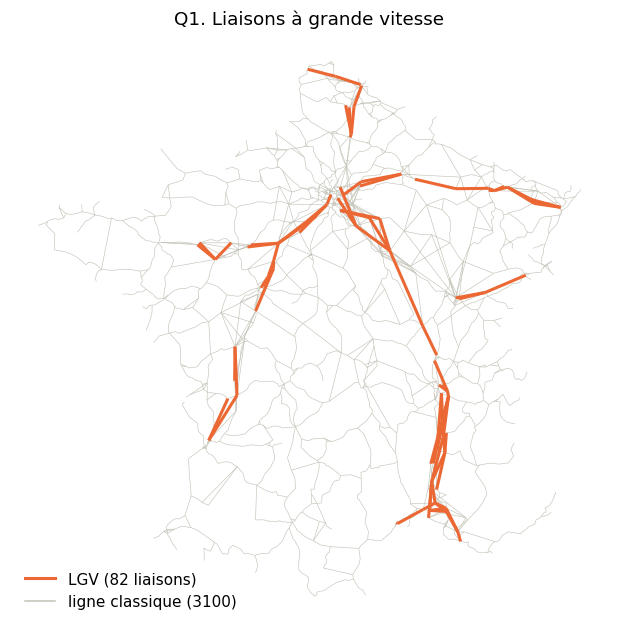

In [5]:
lgv = liaisons[liaisons["type_ligne"] == "LGV"]
fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, zip(liaisons.source, liaisons.target))
tracer_liaisons(ax, zip(lgv.source, lgv.target), couleur=ORANGE, epaisseur=2)
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2, label=f"LGV ({len(lgv)} liaisons)"),
                   Line2D([], [], color=GRIS, lw=1, label=f"ligne classique ({len(liaisons) - len(lgv)})")],
          loc="lower left", frameon=False)
carte(ax, "Q1. Liaisons à grande vitesse")
plt.savefig(FIGURES / "Q1_LGV.png", bbox_inches="tight")
plt.show()

**Figure 1 — Les lignes à grande vitesse.** Orange : les 82 liaisons dont plus de la moitié du tracé est sur LGV ; gris : lignes classiques. Le réseau à grande vitesse forme une **étoile centrée sur Paris** (Sud-Est vers Lyon et Marseille, Atlantique vers Bordeaux et Rennes, Nord vers Lille, Est vers Strasbourg). Seules la LGV Rhin-Rhône et le contournement Nîmes-Montpellier n'en partent pas.

In [6]:
if CYTOSCAPE:  # Style → Edge → Stroke Color et Width : colonne type_ligne, Discrete Mapping
    cy_style("Q1_LGV", BASE, noeud=2)
    p4c.set_edge_color_mapping("type_ligne", ["LGV", "classique"], [ORANGE, GRIS], mapping_type="d", style_name="Q1_LGV")
    p4c.set_edge_line_width_mapping("type_ligne", ["LGV", "classique"], [5, 1], mapping_type="d", style_name="Q1_LGV")
    cy_figure("Q1_LGV", BASE)

## Q2. Où circulent les trains ?

**Notion du cours** : un **graphe pondéré** associe un poids à chaque arête, ici le nombre de trains par jour (deux sens, un mardi type).
**Méthode** : épaisseur des arêtes proportionnelle au poids.

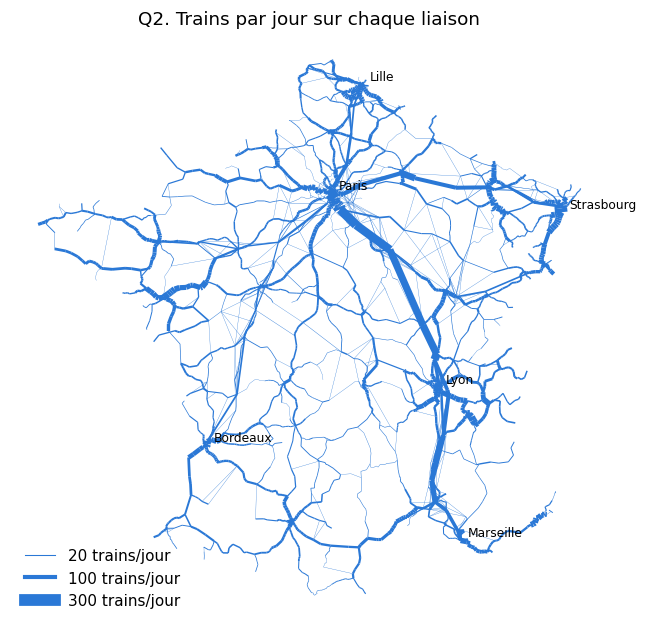

Liaisons sans aucun train ce jour-là : 20%


In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, zip(liaisons.source, liaisons.target), couleur=BLEU, epaisseur=0.2 + liaisons["nb_trains_jour"] / 40)
nommer(ax, ["75056", "69123", "59350", "67482", "13055", "33063"])  # Paris, Lyon, Lille, Strasbourg, Marseille, Bordeaux
ax.legend(handles=[Line2D([], [], color=BLEU, lw=0.2 + n / 40, label=f"{n} trains/jour") for n in (20, 100, 300)],
          loc="lower left", frameon=False)
carte(ax, "Q2. Trains par jour sur chaque liaison")
plt.savefig(FIGURES / "Q2_trains.png", bbox_inches="tight")
plt.show()
print(f"Liaisons sans aucun train ce jour-là : {(liaisons.nb_trains_jour == 0).mean():.0%}")

**Figure 2 — Les trains d'un mardi type.** Épaisseur : nombre de trains par jour sur chaque liaison. Les liaisons les plus chargées dessinent les grands axes (Paris-Lyon-Marseille, Paris-Strasbourg, Paris-Lille) et des étoiles régionales autour de Lyon, Strasbourg et Lille. Une liaison sur cinq n'a aucun train : surtout la banlieue parisienne (Transilien et RER absents des données) et des lignes fermées aux voyageurs.

In [8]:
if CYTOSCAPE:  # Style → Edge → Width : colonne nb_trains_jour, Continuous Mapping
    cy_etiquettes(["75056", "69123", "59350", "67482", "13055", "33063"])
    cy_style("Q2_trains", BASE, noeud=2)
    p4c.set_edge_line_width_mapping("nb_trains_jour", [0, liaisons.nb_trains_jour.max()], [0.5, 14], style_name="Q2_trains")
    p4c.set_edge_color_mapping("nb_trains_jour", [0, liaisons.nb_trains_jour.max()], ["#9ec5f4", BLEU], style_name="Q2_trains")
    cy_figure("Q2_trains", BASE)

## Q3. Quelles villes sont proches de tout le réseau ?

**Notion du cours** : la **closeness** $C(v) = \dfrac{n-1}{\sum_u d(v,u)}$, où $d(v,u)$ est la longueur du plus court chemin ; son inverse, la **farness**, est la distance moyenne de $v$ à tous les autres nœuds.
**Méthode** : `nx.closeness_centrality` sur le réseau principal, plus courts chemins en km de rail ; couleur des villes = closeness.

,ville,farness_km
91216,Épinay-sur-Orge,375.0
91326,Juvisy-sur-Orge,375.0
91136,Champlan,376.0
91027,Athis-Mons,376.0
91549,Sainte-Geneviève-des-Bois,376.0
06062,Fontan,879.0
06163,Tende,892.0
06162,La Brigue,895.0


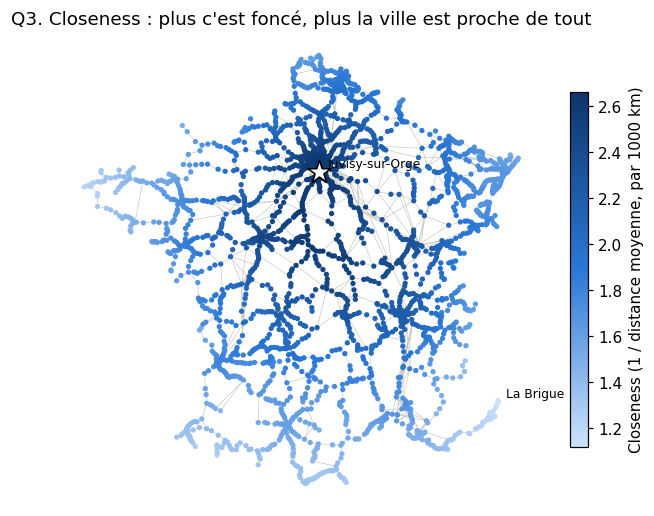

In [9]:
closeness = pd.Series(nx.closeness_centrality(P, distance=POIDS))
farness = 1 / closeness  # km en moyenne vers toutes les autres villes
display(pd.DataFrame({"ville": villes.nom, "farness_km": farness.round(0)}).dropna()
        .sort_values("farness_km").iloc[[0, 1, 2, 3, 4, -3, -2, -1]])

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, P.edges())
tracer_villes(ax, closeness * 1000, "Closeness (1 / distance moyenne, par 1000 km)")
nommer(ax, [closeness.idxmax()], etoile=True)
nommer(ax, [closeness.idxmin()])
carte(ax, "Q3. Closeness : plus c'est foncé, plus la ville est proche de tout")
plt.savefig(FIGURES / "Q3_closeness.png", bbox_inches="tight")
plt.show()

**Figure 3 — Closeness.** Plus une ville est foncée, plus elle est proche, en moyenne, de toutes les autres (étoile : maximum). La ville la plus proche de tout est **Juvisy-sur-Orge** (375 km en moyenne), au croisement des radiales du sud de Paris et de la grande ceinture ; la plus éloignée est La Brigue, au bout de la ligne de Tende (895 km). La closeness décroît régulièrement depuis l'Île-de-France : c'est la signature d'un réseau **radial**.

In [10]:
if CYTOSCAPE:  # Style → Node → Fill Color : colonne closeness, Continuous Mapping
    cy_colonne(closeness, "closeness")
    cy_etiquettes([closeness.idxmax(), closeness.idxmin()])
    cy_style("Q3_closeness", BASE, noeud=10)
    p4c.set_node_color_mapping("closeness", [closeness.min(), closeness.max()], ["#cde2fb", "#0d366b"], style_name="Q3_closeness")
    cy_figure("Q3_closeness", BASE)

## Q4. Où est le centre du réseau, où est sa périphérie ?

**Notion du cours** : l'**excentricité** $e(v) = \max_u d(v,u)$ est la distance d'un nœud à son nœud le plus éloigné. Le **rayon** est l'excentricité minimale (atteinte au **centre**), le **diamètre** l'excentricité maximale (atteinte à la **périphérie**). La closeness regarde la distance **moyenne**, l'excentricité la distance **au pire**.
**Méthode** : `nx.eccentricity` en km ; le plus court chemin entre les deux villes de la périphérie est le trajet le plus long de France.

Rayon : 746 km, centre : Montluçon
Diamètre : 1487 km, périphérie : La Brigue, Brest
Trajet le plus long : 144 villes traversées, via Nice, Toulon, Marseille, Nîmes, Clermont-Ferrand, Le Mans, Rennes, Brest


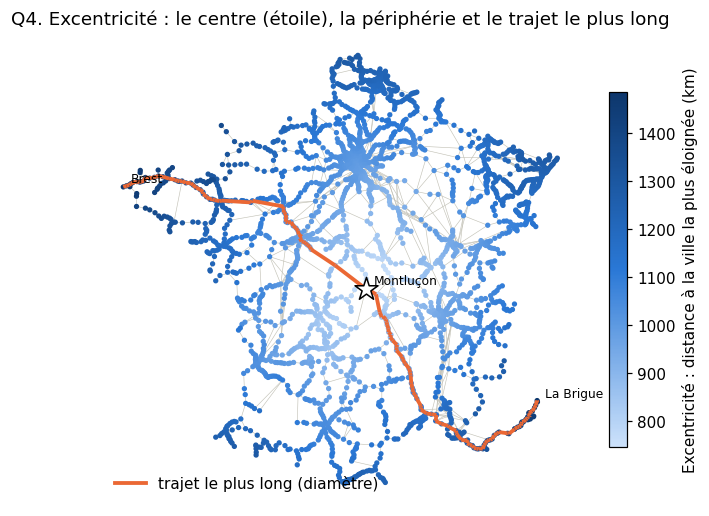

In [11]:
excentricite = pd.Series(nx.eccentricity(P, weight=POIDS))
centre = excentricite[excentricite == excentricite.min()].index
peripherie = excentricite[excentricite == excentricite.max()].index
print(f"Rayon : {excentricite.min():.0f} km, centre : {', '.join(villes.nom[centre])}")
print(f"Diamètre : {excentricite.max():.0f} km, périphérie : {', '.join(villes.nom[peripherie])}")
plus_long = nx.shortest_path(P, peripherie[0], peripherie[-1], weight=POIDS)  # le trajet le plus long de France
print(f"Trajet le plus long : {len(plus_long) - 2} villes traversées, via",
      ", ".join(villes.nom[v] for v in plus_long if villes.population[v] > 100000))

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, P.edges())
tracer_villes(ax, excentricite, "Excentricité : distance à la ville la plus éloignée (km)")
tracer_liaisons(ax, zip(plus_long, plus_long[1:]), couleur=ORANGE, epaisseur=2.5)
nommer(ax, centre, etoile=True)
nommer(ax, peripherie)
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2.5, label="trajet le plus long (diamètre)")], loc="lower left", frameon=False)
carte(ax, "Q4. Excentricité : le centre (étoile), la périphérie et le trajet le plus long")
plt.savefig(FIGURES / "Q4_excentricite.png", bbox_inches="tight")
plt.show()

**Figure 4 — Excentricité, centre et périphérie.** Couleur : distance de chaque ville à la ville la plus éloignée ; étoile : le centre, **Montluçon** (rayon 746 km) ; orange : le **trajet le plus long de France** (diamètre), de Brest à La Brigue, 1 487 km de rail pour 1 042 km à vol d'oiseau, 144 villes traversées et aucun km de LGV. La closeness place le centre là où se trouve la masse des villes (Île-de-France), l'excentricité au milieu géographique du pays. Les distances étant en km et non en temps, les LGV ne « rapprochent » pas les villes.

In [12]:
if CYTOSCAPE:  # Fill Color : colonne excentricite (Continuous) ; Size et Edge Color : colonnes de rôle (Discrete)
    cy_colonne(excentricite, "excentricite")
    role = pd.Series("", index=villes.index)
    role[list(centre)] = "centre"
    role[list(peripherie)] = "périphérie"
    cy_colonne(role, "role_q4")
    chemin = pd.Series("", index=liaisons.cle)
    chemin[[cle_arete(a, b) for a, b in zip(plus_long, plus_long[1:])]] = "trajet le plus long"
    cy_colonne(chemin, "chemin_q4", table="edge")
    cy_etiquettes(list(centre) + list(peripherie))
    cy_style("Q4_excentricite", BASE, noeud=10)
    p4c.set_node_color_mapping("excentricite", [excentricite.min(), excentricite.max()], ["#cde2fb", "#0d366b"], style_name="Q4_excentricite")
    p4c.set_node_size_mapping("role_q4", ["centre", "périphérie"], [45, 30], mapping_type="d", style_name="Q4_excentricite")
    p4c.set_edge_color_mapping("chemin_q4", ["trajet le plus long"], [ORANGE], mapping_type="d", style_name="Q4_excentricite")
    p4c.set_edge_line_width_mapping("chemin_q4", ["trajet le plus long"], [6], mapping_type="d", style_name="Q4_excentricite")
    cy_figure("Q4_excentricite", BASE)

## Q5. Quels sont les points névralgiques ?

**Notion du cours** : la **betweenness** d'un nœud est la part des plus courts chemins qui passent par lui ; l'**edge betweenness** est la même mesure pour une arête. Un nœud de forte betweenness est un point de passage obligé (comme un *choke point* d'un réseau métabolique).
**Méthode** : taille et couleur des villes = betweenness ; épaisseur des liaisons = edge betweenness.

,ville,betweenness
75056,Paris,0.290
93066,Saint-Denis,0.163
60175,Creil,0.140
18279,Vierzon,0.139
69123,Lyon,0.133
95268,Garges-lès-Gonesse,0.132
95019,Arnouville,0.132
95280,Goussainville,0.132


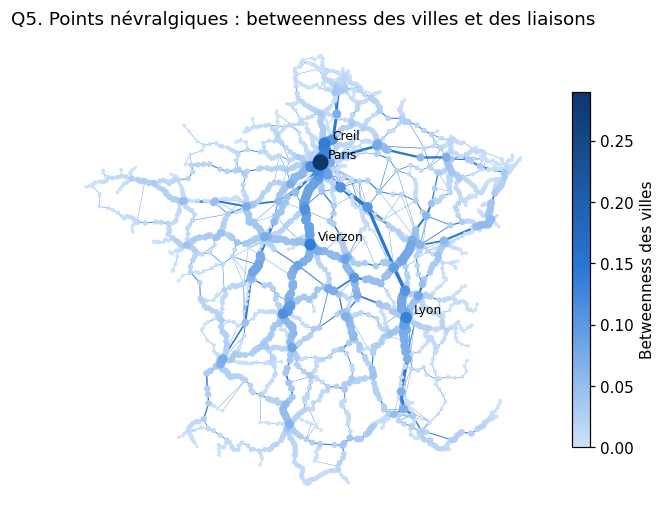

In [13]:
betweenness = pd.Series(nx.betweenness_centrality(P, weight=POIDS))
eb = nx.edge_betweenness_centrality(P, weight=POIDS)
liaisons["edge_betweenness"] = [eb.get((a, b), eb.get((b, a), 0)) for a, b in zip(liaisons.source, liaisons.target)]
nevralgiques = betweenness.nlargest(8).index
display(pd.DataFrame({"ville": villes.nom[nevralgiques], "betweenness": betweenness[nevralgiques].round(3)}))

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, zip(liaisons.source, liaisons.target), couleur=BLEU, epaisseur=0.2 + 25 * liaisons["edge_betweenness"])
tracer_villes(ax, betweenness, "Betweenness des villes", taille=2 + 300 * betweenness)
nommer(ax, [v for v in nevralgiques if villes.region[v] != "11"][:4] + ["75056"])  # hors banlieue, pour la lisibilité
carte(ax, "Q5. Points névralgiques : betweenness des villes et des liaisons")
plt.savefig(FIGURES / "Q5_betweenness.png", bbox_inches="tight")
plt.show()

**Figure 5 — Points névralgiques.** **Paris** porte 29 % des plus courts chemins, devant la banlieue nord (Saint-Denis, Creil : passage vers Lille), **Vierzon** et **Lyon**. Vierzon, peu fréquentée, est incontournable : c'est là que se croisent l'axe Paris-Toulouse et la transversale Nantes-Lyon. Les liaisons les plus épaisses forment l'ossature du réseau : Paris-Orléans-Limoges-Toulouse et Paris-Lyon-Marseille.

In [14]:
if CYTOSCAPE:  # Node Size : colonne betweenness ; Edge Width : colonne edge_betweenness (Continuous Mapping)
    cy_colonne(betweenness, "betweenness")
    cy_colonne(liaisons.set_index("cle")["edge_betweenness"], "edge_betweenness", table="edge")
    cy_etiquettes([v for v in nevralgiques if villes.region[v] != "11"][:4] + ["75056"])
    cy_style("Q5_betweenness", BASE)
    p4c.set_node_size_mapping("betweenness", [0, betweenness.max()], [4, 60], style_name="Q5_betweenness")
    p4c.set_node_color_mapping("betweenness", [0, betweenness.max()], ["#cde2fb", "#0d366b"], style_name="Q5_betweenness")
    p4c.set_edge_line_width_mapping("edge_betweenness", [0, liaisons.edge_betweenness.max()], [0.5, 12], style_name="Q5_betweenness")
    cy_figure("Q5_betweenness", BASE)

## Q6. Que se passe-t-il si on retire les villes les plus importantes ?

**Notion du cours** : la **robustesse** d'un réseau. On retire des nœuds et on observe la **plus grande composante connexe** (combien de villes restent reliées) et la longueur des **plus courts chemins**.

Quatre tests :
1. **retirer Paris**, la ville de plus forte betweenness : que deviennent les trajets de la promotion vers Rouen ?
2. **retirer chaque point d'articulation** (nœud dont le retrait coupe le graphe) : quel retrait isole le plus de villes ?
3. **retraits successifs** : attaque ciblée (betweenness décroissante) contre panne aléatoire ;
4. **retirer les 10 villes de plus forte betweenness**, une à une : composantes, trajets coupés, allongement des plus courts chemins.

In [15]:
ROUEN = "76540"  # notre université
ORIGINES = {"Paris": "75056", "Évry": "91228", "Nantes": "44109", "Dijon": "21231",
            "Lyon": "69123", "Montpellier": "34172", "Toulouse": "31555"}  # villes de la promotion


def trajets_vers_rouen(H):
    """Plus court chemin (km) de chaque ville de la promotion présente dans H jusqu'à Rouen (None si coupé)."""
    d = nx.single_source_dijkstra_path_length(H, ROUEN, weight=POIDS)
    return {nom: d.get(v) for nom, v in ORIGINES.items() if v in H}


# Test 1 : sans Paris
sans_paris = P.copy()
sans_paris.remove_node(ORIGINES["Paris"])
test1 = pd.DataFrame({"km avec Paris": trajets_vers_rouen(P), "km sans Paris": trajets_vers_rouen(sans_paris)}).dropna()
test1["allongement_km"] = test1["km sans Paris"] - test1["km avec Paris"]
print(f"Sans Paris : {sans_paris.number_of_nodes() - len(max(nx.connected_components(sans_paris), key=len))} ville(s) isolée(s)")
display(test1.round(0))

Sans Paris : 0 ville(s) isolée(s)


,km avec Paris,km sans Paris,allongement_km
Évry,154.0,154.0,0.0
Nantes,476.0,476.0,0.0
Dijon,438.0,439.0,1.0
Lyon,580.0,581.0,1.0
Montpellier,886.0,886.0,0.0
Toulouse,827.0,827.0,0.0


In [16]:
# Test 2 : le retrait de quel point d'articulation isole le plus de villes ?
isolees = {}
for v in nx.articulation_points(P):
    H = P.copy()
    H.remove_node(v)
    isolees[v] = P.number_of_nodes() - 1 - len(max(nx.connected_components(H), key=len))
isolees = pd.Series(isolees).sort_values(ascending=False)
print(f"{len(isolees)} points d'articulation ({len(isolees) / P.number_of_nodes():.0%} des villes)")

pire = isolees.index[0]
H = P.copy()
H.remove_node(pire)
coupees = set(P) - max(nx.connected_components(H), key=len) - {pire}
print(f"Pire retrait : {villes.nom[pire]}, qui coupe {len(coupees)} villes du réseau")

318 points d'articulation (12% des villes)
Pire retrait : Carnoules, qui coupe 34 villes du réseau


In [17]:
# Test 3 : retraits successifs, attaque ciblée contre panne aléatoire
def part_reliee(ordre, n=300, pas=10):
    """Retire les villes de `ordre` une à une ; part des villes restant dans la plus grande composante."""
    H, resultat = P.copy(), {0: 1.0}
    for i, v in enumerate(ordre[:n], start=1):
        H.remove_node(v)
        if i % pas == 0:
            resultat[i] = len(max(nx.connected_components(H), key=len)) / P.number_of_nodes()
    return pd.Series(resultat)


attaque = part_reliee(list(betweenness.sort_values(ascending=False).index))
random.seed(1)
panne = sum(part_reliee(random.sample(list(P), 300)) for _ in range(10)) / 10  # moyenne de 10 tirages

In [18]:
# Test 4 : retrait, une à une, des 10 villes de plus forte betweenness
top10 = list(betweenness.nlargest(10).index)
random.seed(2)
autres = [v for v in P if v not in top10]
paires = [tuple(random.sample(autres, 2)) for _ in range(300)]  # 300 trajets tirés au hasard, les mêmes à chaque étape
reference = {(a, b): nx.shortest_path_length(P, a, b, weight=POIDS) for a, b in paires}


def connectivite(H):
    # composantes connexes, part des villes dans la plus grande, trajets coupés et allongement des autres
    composantes = list(nx.connected_components(H))
    coupes, allongements = 0, []
    for a, b in paires:
        try:
            allongements.append(nx.shortest_path_length(H, a, b, weight=POIDS) / reference[(a, b)] - 1)
        except nx.NetworkXNoPath:
            coupes += 1
    return {"composantes": len(composantes), "plus grande composante (%)": 100 * max(map(len, composantes)) / P.number_of_nodes(),
            "trajets coupés (sur 300)": coupes, "allongement moyen (%)": 100 * np.mean(allongements)}


sans_top10_g = P.copy()
etapes = [{"ville retirée": "aucune", **connectivite(sans_top10_g)}]
for v in top10:
    sans_top10_g.remove_node(v)
    etapes.append({"ville retirée": villes.nom[v], **connectivite(sans_top10_g)})
etapes = pd.DataFrame(etapes)
display(etapes.round(2))
detachees = set(sans_top10_g) - max(nx.connected_components(sans_top10_g), key=len)

,ville retirée,composantes,plus grande composante (%),trajets coupés (sur 300),allongement moyen (%)
0,aucune,1,100.00,0,0.00
1,Paris,1,99.96,0,0.81
2,Saint-Denis,1,99.92,0,1.07
3,Creil,1,99.88,0,2.28
4,Vierzon,1,99.85,0,3.86
5,Lyon,1,99.81,0,4.56
6,Garges-lès-Gonesse,1,99.77,0,4.56
7,Arnouville,1,99.73,0,4.56
8,Goussainville,2,99.54,0,4.56
9,Louvres,2,99.54,0,4.56


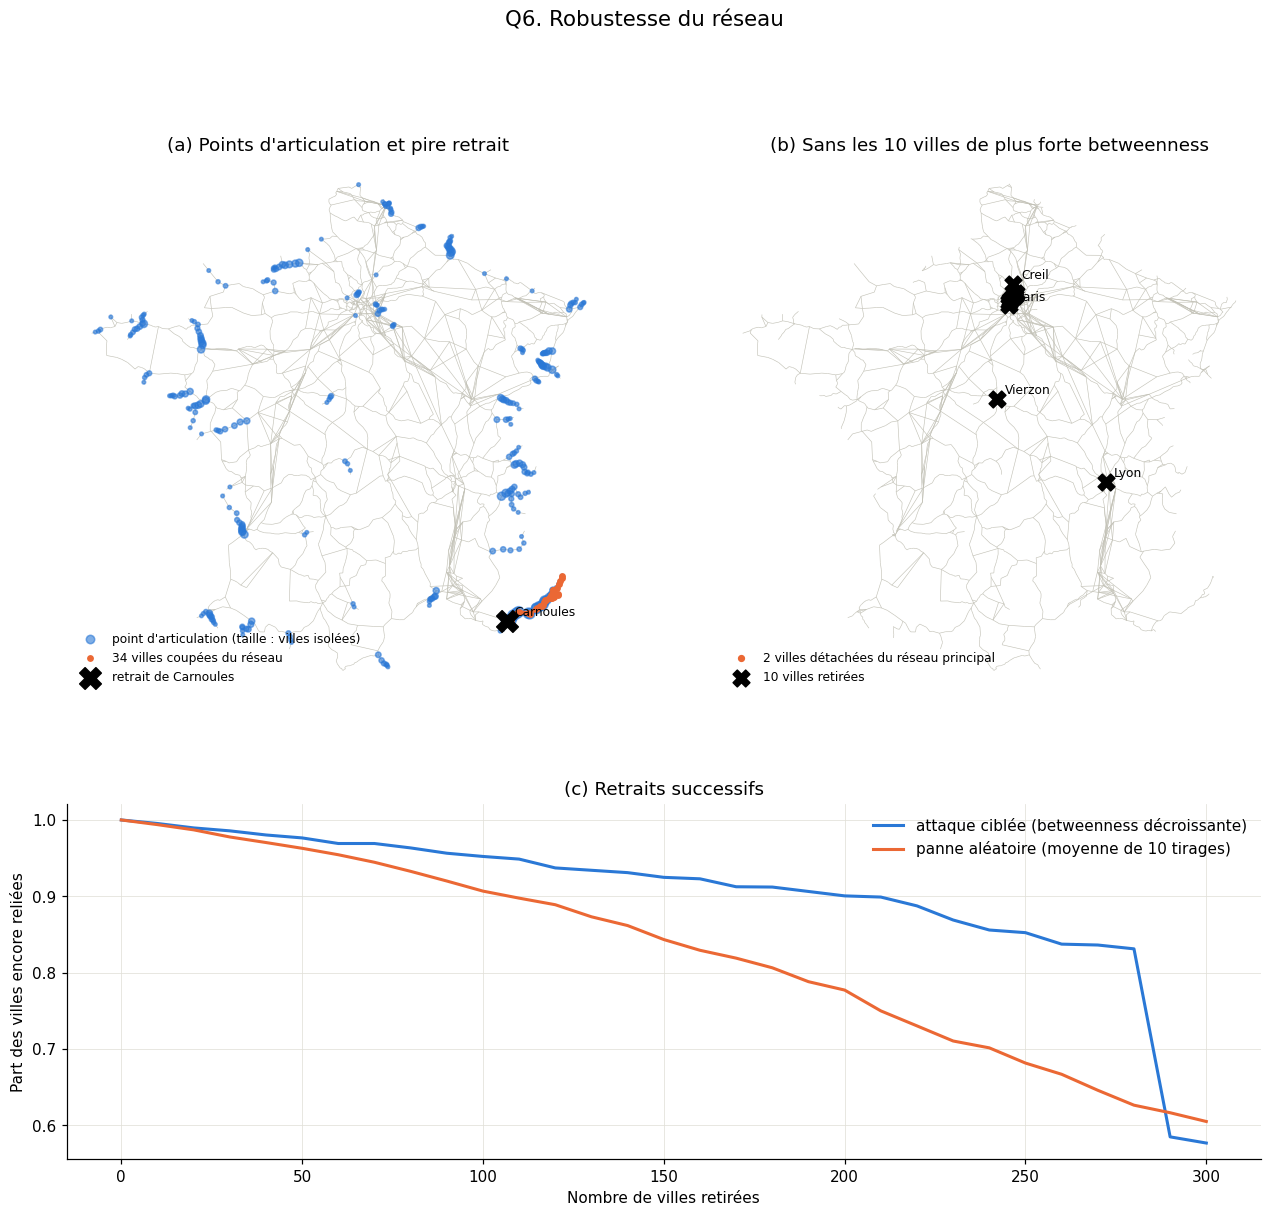

In [19]:
fig = plt.figure(figsize=(14, 12))
grille = fig.add_gridspec(2, 2, height_ratios=[1.6, 1])

# (a) points d'articulation et effet du pire retrait
ax = fig.add_subplot(grille[0, 0])
tracer_liaisons(ax, P.edges())
art = isolees[isolees > 0]
ax.scatter(villes.lon[art.index], villes.lat[art.index], s=4 + 1.5 * art, color=BLEU, alpha=0.6, zorder=2,
           label="point d'articulation (taille : villes isolées)")
tracer_liaisons(ax, P.subgraph(coupees | {pire}).edges(), couleur=ORANGE, epaisseur=2.5)
ax.scatter(villes.lon[list(coupees)], villes.lat[list(coupees)], s=12, color=ORANGE, zorder=3,
           label=f"{len(coupees)} villes coupées du réseau")
ax.scatter(villes.lon[pire], villes.lat[pire], s=200, marker="X", color="black", zorder=4, label=f"retrait de {villes.nom[pire]}")
nommer(ax, [pire])
ax.legend(frameon=False, loc="lower left", fontsize=8)
carte(ax, "(a) Points d'articulation et pire retrait")

# (b) le réseau sans ses 10 villes de plus forte betweenness
ax = fig.add_subplot(grille[0, 1])
tracer_liaisons(ax, sans_top10_g.edges())
ax.scatter(villes.lon[list(detachees)], villes.lat[list(detachees)], s=14, color=ORANGE, zorder=2,
           label=f"{len(detachees)} villes détachées du réseau principal")
ax.scatter(villes.lon[top10], villes.lat[top10], s=120, marker="X", color="black", zorder=3, label="10 villes retirées")
nommer(ax, [v for v in top10 if villes.region[v] != "11"] + ["75056"])
ax.legend(frameon=False, loc="lower left", fontsize=8)
carte(ax, "(b) Sans les 10 villes de plus forte betweenness")

# (c) retraits successifs : attaque ciblée contre panne aléatoire
ax = fig.add_subplot(grille[1, :])
ax.plot(attaque, color=BLEU, lw=2, label="attaque ciblée (betweenness décroissante)")
ax.plot(panne, color=ORANGE, lw=2, label="panne aléatoire (moyenne de 10 tirages)")
ax.set_xlabel("Nombre de villes retirées")
ax.set_ylabel("Part des villes encore reliées")
ax.grid(color="#e1e0d9", lw=0.5)
ax.legend(frameon=False)
ax.set_title("(c) Retraits successifs")

fig.suptitle("Q6. Robustesse du réseau", fontsize=14)
plt.savefig(FIGURES / "Q6_robustesse.png", bbox_inches="tight")
plt.show()

**Figure 6 — Robustesse du réseau.** (a) Points d'articulation (bleu, taille : nombre de villes isolées par leur retrait) et pire retrait (croix). (b) Réseau privé de ses 10 villes de plus forte betweenness. (c) Part des villes encore reliées quand on retire les villes une à une.
Le réseau est **redondant au centre et fragile en périphérie** :
- **sans Paris** (test 1), aucune ville n'est isolée et les trajets vers Rouen s'allongent d'1 km au plus : la grande ceinture contourne la capitale ;
- **12 % des villes sont des points d'articulation**, surtout sur des lignes en antenne. Les plus critiques sont sur Marseille-Vintimille : retirer **Carnoules** coupe 34 villes de la Côte d'Azur (a) ;
- **sans les 10 villes de plus forte betweenness**, 99,5 % des villes restent reliées et aucun des 300 trajets tirés au hasard n'est coupé (b), mais les trajets s'allongent de 4,6 % : surtout à cause de Vierzon (+1,6 point), Creil (+1,2), Paris (+0,8) et Lyon (+0,7). Les 5 dernières villes, sur la même ligne que Saint-Denis et Creil, n'ajoutent plus rien : leur betweenness était redondante ;
- **les pannes aléatoires dégradent le réseau plus vite que l'attaque ciblée** jusqu'à environ 280 retraits (c) : une panne au hasard tombe souvent sur une ligne en antenne, alors que les villes centrales sont dans des zones maillées. Au-delà, l'attaque fait s'effondrer le réseau (de 83 % à 58 % de villes reliées).

In [20]:
if CYTOSCAPE:  # Node Size : colonne villes_isolees ; puis copie du réseau et Edit → Delete Selected Nodes
    cy_colonne(isolees.reindex(villes.index, fill_value=0), "villes_isolees")
    etat = pd.Series("", index=villes.index)
    etat[list(coupees)] = "coupée"
    cy_colonne(etat, "etat_q6")
    cy_etiquettes([pire])
    copie = p4c.clone_network(BASE)  # on supprime la ville dans une copie, pour garder le réseau complet
    p4c.select_nodes([pire], by_col="cle", preserve_current_selection=False, network=copie)
    p4c.delete_selected_nodes(network=copie)
    cy_style("Q6_articulation", copie, noeud=4)
    p4c.set_node_size_mapping("villes_isolees", [0, isolees.max()], [4, 40], style_name="Q6_articulation")
    p4c.set_node_color_mapping("etat_q6", ["coupée"], [ORANGE], mapping_type="d", default_color="#9ec5f4", style_name="Q6_articulation")
    cy_figure("Q6_articulation", copie)

    # même chose sans les 10 villes : sélection des 10 villes (Select → Nodes), Edit → Delete Selected Nodes
    etat = pd.Series("principal", index=villes.index)
    etat[list(detachees)] = "détachée"
    cy_colonne(etat, "etat_top10")
    sans_top10 = p4c.clone_network(BASE)
    p4c.select_nodes(top10, by_col="cle", preserve_current_selection=False, network=sans_top10)
    p4c.delete_selected_nodes(network=sans_top10)
    cy_style("Q6_sans_top10", sans_top10, noeud=4, etiquette=None)
    p4c.set_node_color_mapping("etat_top10", ["principal", "détachée"], ["#9ec5f4", ORANGE], mapping_type="d", style_name="Q6_sans_top10")
    p4c.set_node_size_mapping("etat_top10", ["principal", "détachée"], [4, 14], mapping_type="d", style_name="Q6_sans_top10")
    cy_figure("Q6_sans_top10", sans_top10)

## Q7. Les trajets de la promotion vers Rouen

**Notion du cours** : le **plus court chemin pondéré** (Dijkstra), hypothèse « parcimonieuse » qui ne tient pas toujours dans la réalité ; le **sous-graphe** formé par plusieurs chemins ; la **vue schématique** (carte KEGG, plan de métro de Tokyo : *« the map is not the territory »*).

**Méthode** : de **Paris, Évry, Nantes, Dijon, Lyon, Montpellier et Toulouse** vers **Rouen**, notre université, trois distances :
- **vol d'oiseau** : la ligne droite ;
- **plus court chemin dans le graphe** : sur toutes les voies exploitées, le long du tracé ;
- **trajet réel** : plus court chemin sur les seules liaisons où circule au moins un train ce mardi-là (en Île-de-France, faute de données Transilien, toutes les liaisons sont gardées).

Le **plan de métro** sacrifie les distances pour la lisibilité : stations sur une grille, tronçons à 45° ou 90°, une couleur par itinéraire, tronçons partagés dessinés côte à côte, région parisienne agrandie. Les stations sont les villes de départ, Rouen, les jonctions entre itinéraires et les villes de plus de 100 000 habitants hors Île-de-France.

In [21]:
def vol_oiseau_km(a, b):
    """Distance en ligne droite (km) ; un degré de longitude vaut 111,32 x cos(46,5°) km en France."""
    return math.hypot((villes.lon[a] - villes.lon[b]) * 111.32 * math.cos(math.radians(46.5)),
                      (villes.lat[a] - villes.lat[b]) * 110.57)


idf = set(villes.index[villes.region == "11"])
desservi = P.edge_subgraph([(a, b) for a, b, n in P.edges(data="nb_trains_jour") if n > 0 or (a in idf and b in idf)])

trajets = []
for nom, origine in ORIGINES.items():
    chemin_reel = nx.shortest_path(desservi, origine, ROUEN, weight=POIDS)
    trajets.append({"trajet": f"{nom} → Rouen", "vol_oiseau": vol_oiseau_km(origine, ROUEN),
                    "graphe": nx.shortest_path_length(P, origine, ROUEN, weight=POIDS),
                    "reel": nx.path_weight(desservi, chemin_reel, weight=POIDS),
                    "villes_traversees": len(chemin_reel) - 2,
                    "via": ", ".join(villes.nom[v] for v in chemin_reel[1:-1] if villes.population[v] > 60000),
                    "chemin_reel": chemin_reel})
trajets = pd.DataFrame(trajets).set_index("trajet").sort_values("vol_oiseau")
trajets["detour_reel"] = trajets["reel"] / trajets["vol_oiseau"]
display(trajets.drop(columns="chemin_reel").round(2))

,vol_oiseau,graphe,reel,villes_traversees,via,detour_reel
trajet,,,,,,
Paris → Rouen,115.41,133.05,133.05,23,"Issy-les-Moulineaux, Versailles",1.15
Évry → Rouen,137.01,153.69,153.69,32,Versailles,1.12
Nantes → Rouen,318.89,475.99,475.99,42,"Angers, Le Mans",1.49
Dijon → Rouen,382.31,438.00,438.00,43,"Créteil, Paris, Issy-les-Moulineaux, Versailles",1.15
Lyon → Rouen,499.68,580.31,580.31,48,"Créteil, Paris, Issy-les-Moulineaux, Versailles",1.16
Toulouse → Rouen,645.72,827.48,827.48,97,"Montauban, Limoges, Versailles",1.28
Montpellier → Rouen,680.53,886.05,888.23,78,"Nîmes, Avignon, Valence, Lyon, Créteil, Paris,...",1.31


In [22]:
def decaler(points, d):
    """Polyligne décalée de `d` sur sa gauche, avec des coins en onglet (comme une voie parallèle)."""
    normales = [np.array([p[1] - q[1], q[0] - p[0]]) / np.linalg.norm(q - p) for p, q in zip(points, points[1:])]
    sortie = [points[0] + d * normales[0]]
    for n1, n2, p in zip(normales, normales[1:], points[1:-1]):
        m = (n1 + n2) / np.linalg.norm(n1 + n2)
        sortie.append(p + d * m / np.dot(m, n1))
    return sortie + [points[-1] + d * normales[-1]]


def plan_metro(ax, itineraires, pas=0.5, ecart=0.045, loupe=0.5):
    """Dessine des itinéraires (nom -> liste de villes) à la manière d'un plan de métro."""
    # 1. Stations : départs, arrivée, jonctions (ville où arrivent deux itinéraires venant de villes différentes)
    #    et villes de plus de 100 000 habitants hors Île-de-France
    precedents = {}
    for chemin in itineraires.values():
        for avant, v in zip(chemin, chemin[1:]):
            precedents.setdefault(v, set()).add(avant)
    jonctions = {v for v, avant in precedents.items() if len(avant) > 1} | {c[0] for c in itineraires.values()}
    lignes = {nom: [v for i, v in enumerate(chemin) if i == len(chemin) - 1 or v in jonctions
                    or (villes.population[v] > 100000 and villes.region[v] != "11")]
              for nom, chemin in itineraires.items()}
    # 2. Position : effet de loupe sur Paris (distance au centre élevée à la puissance `loupe`, comme sur un plan
    #    de métro où le centre est agrandi), puis arrondi sur une grille, sans deux stations sur la même case
    centre = np.array([villes.lon[ORIGINES["Paris"]] * 0.69, villes.lat[ORIGINES["Paris"]]])
    position, occupees = {}, set()
    for v in dict.fromkeys(s for stations in lignes.values() for s in stations):
        p = np.array([villes.lon[v] * 0.69, villes.lat[v]]) - centre
        r = np.linalg.norm(p)
        p = p / r * 2 * r ** loupe if r > 0 else p
        x, y = round(p[0] / pas) * pas, round(p[1] / pas) * pas
        while (x, y) in occupees:
            x += pas
        occupees.add((x, y))
        position[v] = np.array([x, y])
    # 3. Tronçons : une diagonale à 45° puis un segment horizontal ou vertical. Les lignes qui partagent un tronçon
    #    sont dessinées côte à côte, toujours dans le même ordre, comme des voies parallèles
    troncons = {}
    for nom, stations in lignes.items():
        for u, v in zip(stations, stations[1:]):
            troncons.setdefault((u, v), []).append(nom)
    for (u, v), noms in troncons.items():
        a, b = position[u], position[v]
        milieu = a + min(abs(b - a)) * np.sign(b - a)
        points = [a] + [p for p in (milieu, b) if not np.allclose(p, a)]
        points = [p for i, p in enumerate(points) if i == 0 or not np.allclose(p, points[i - 1])]
        noms = sorted(noms, key=list(itineraires).index)
        for k, nom in enumerate(noms):
            xs, ys = zip(*decaler(points, ecart * (k - (len(noms) - 1) / 2)))
            ax.plot(xs, ys, color=COULEURS[nom], lw=3.5, solid_capstyle="round", solid_joinstyle="round")
    # 4. Stations : cercles blancs ; départs et arrivée plus grands, nommés au-dessus, jonctions nommées en dessous
    for v, (x, y) in position.items():
        terminus = v in ORIGINES.values() or v == ROUEN
        ax.scatter(x, y, s=170 if terminus else 110, c="white", edgecolors="black", linewidths=2 if terminus else 1.2, zorder=3)
        voisins = [position[w][0] for u, w in troncons if u == v] + [position[u][0] for u, w in troncons if w == v]
        a_gauche = terminus and np.mean(voisins) > x  # nom du côté opposé à la ligne
        ax.annotate(villes.nom[v], (x, y), xytext=(-10, 6) if a_gauche else (8, 6) if terminus else (8, -13),
                    textcoords="offset points", ha="right" if a_gauche else "left",
                    fontsize=9 if terminus else 8, fontweight="bold" if terminus else "normal")
    ax.legend(handles=[Line2D([], [], color=c, lw=5, label=n) for n, c in COULEURS.items()], loc="lower left", frameon=False)
    ax.set_aspect("equal")
    ax.set_axis_off()
    return position, troncons

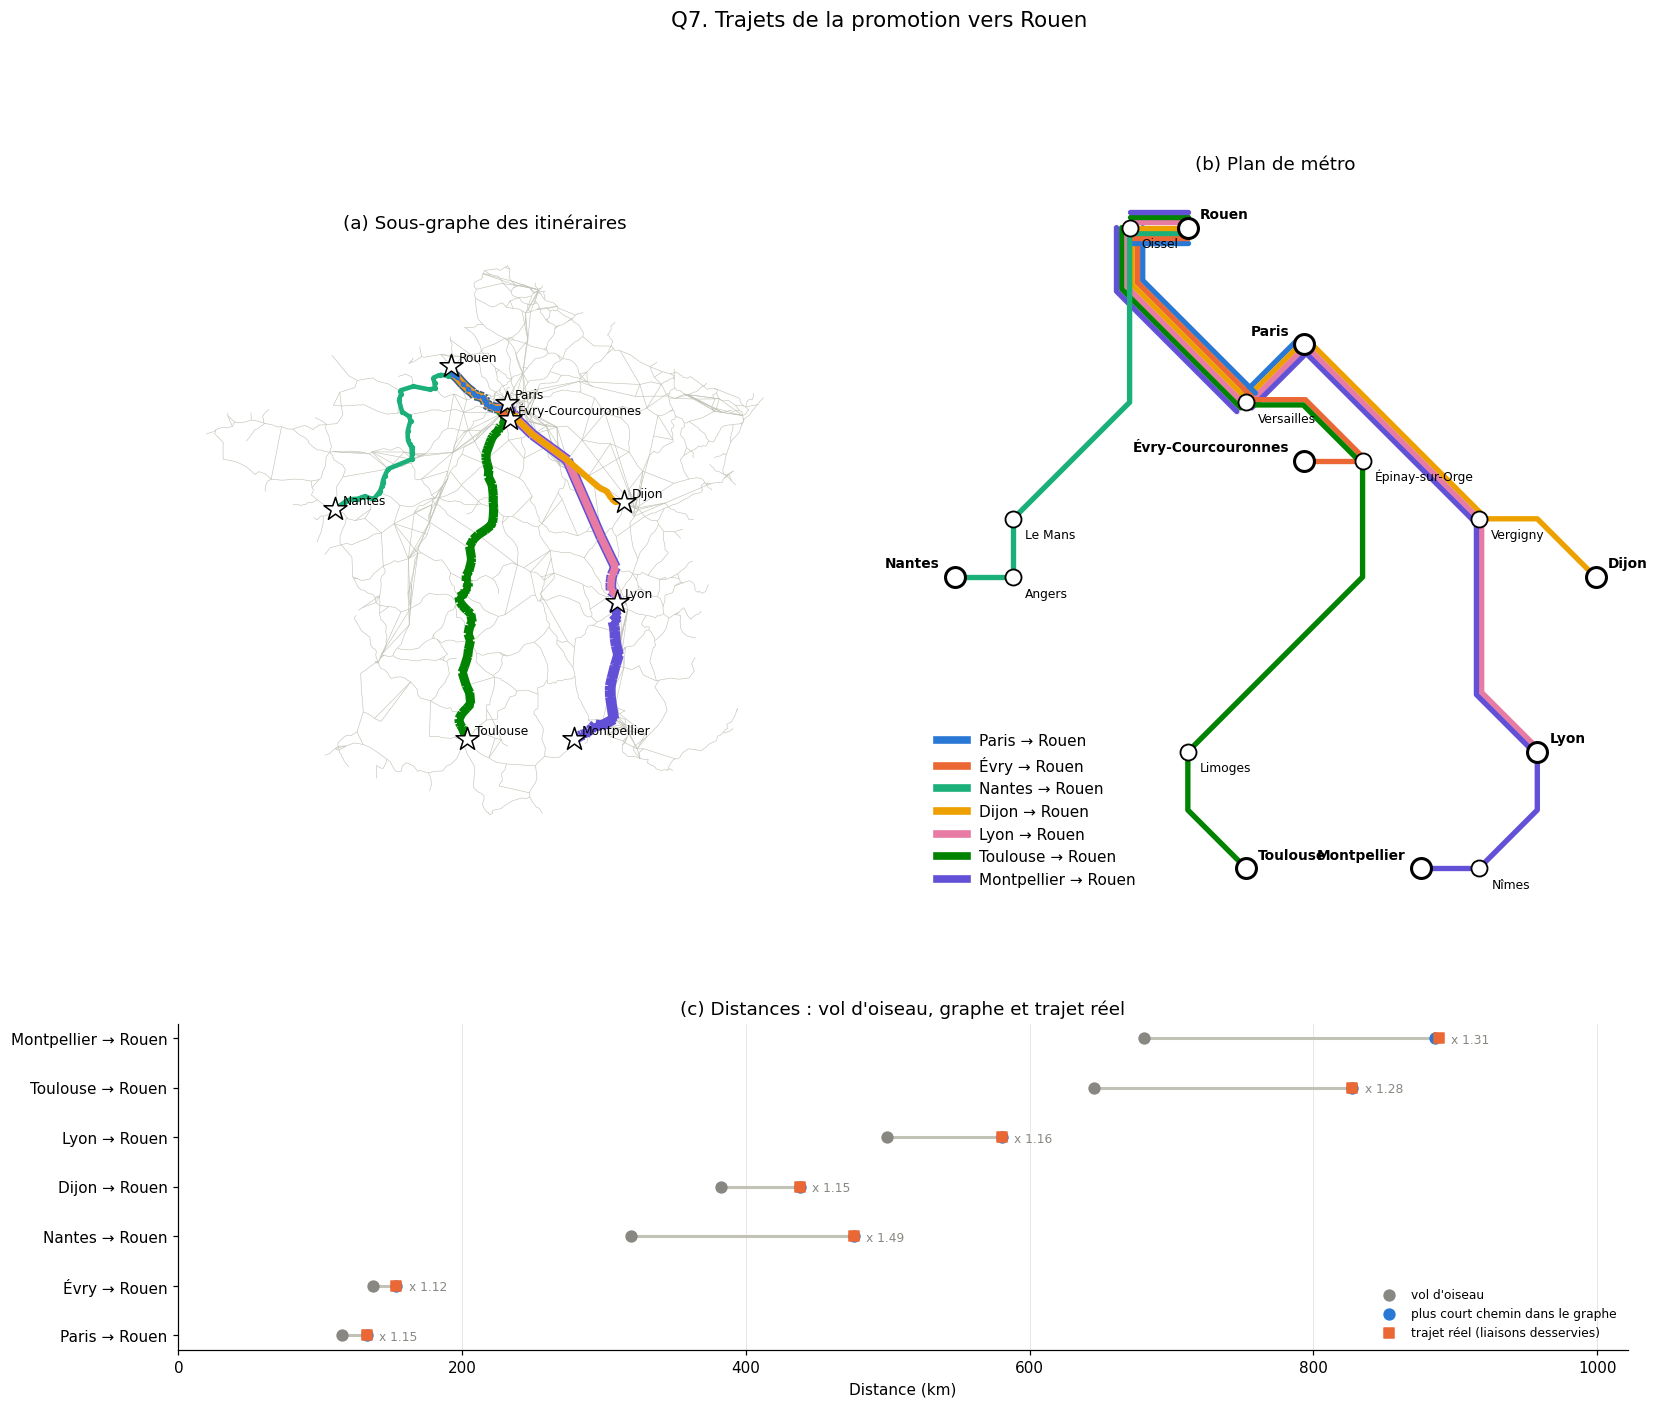

In [23]:
COULEURS = dict(zip(trajets.index, [BLEU, ORANGE, "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
fig = plt.figure(figsize=(17, 14))
grille = fig.add_gridspec(2, 2, height_ratios=[2.3, 1], width_ratios=[1, 1.15])

# (a) sous-graphe des itinéraires, sur la carte
ax = fig.add_subplot(grille[0, 0])
tracer_liaisons(ax, P.edges())
for k, (trajet, chemin) in enumerate(trajets["chemin_reel"][::-1].items()):  # du plus long au plus court
    tracer_liaisons(ax, zip(chemin, chemin[1:]), couleur=COULEURS[trajet], epaisseur=7 - k)
    ax.scatter(villes.lon[chemin], villes.lat[chemin], s=6, color=COULEURS[trajet], zorder=2)
nommer(ax, list(ORIGINES.values()) + [ROUEN], etoile=True)
carte(ax, "(a) Sous-graphe des itinéraires")

# (b) les mêmes itinéraires en plan de métro
ax = fig.add_subplot(grille[0, 1])
position_metro, troncons_metro = plan_metro(ax, trajets["chemin_reel"].to_dict())
ax.set_title("(b) Plan de métro")

# (c) vol d'oiseau, plus court chemin et trajet réel
ax = fig.add_subplot(grille[1, :])
y = range(len(trajets))
ax.hlines(y, trajets.vol_oiseau, trajets[["graphe", "reel"]].max(axis=1), color=GRIS, lw=2)
ax.scatter(trajets.vol_oiseau, y, color="#898781", s=50, label="vol d'oiseau", zorder=2)
ax.scatter(trajets.graphe, y, color=BLEU, s=50, label="plus court chemin dans le graphe", zorder=3)
ax.scatter(trajets.reel, y, color=ORANGE, marker="s", s=45, label="trajet réel (liaisons desservies)", zorder=4)
for i, (x, r) in enumerate(zip(trajets[["graphe", "reel"]].max(axis=1), trajets.detour_reel)):
    ax.annotate(f"x {r:.2f}", (x, i), xytext=(8, -3), textcoords="offset points", fontsize=8, color="#898781")
ax.set_yticks(list(y), trajets.index)
ax.set_xlabel("Distance (km)")
ax.set_xlim(0, trajets[["graphe", "reel"]].max().max() * 1.15)
ax.grid(axis="x", color="#e1e0d9", lw=0.5)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("(c) Distances : vol d'oiseau, graphe et trajet réel")

fig.suptitle("Q7. Trajets de la promotion vers Rouen", fontsize=14)
plt.savefig(FIGURES / "Q7_trajets_rouen.png", bbox_inches="tight")
plt.show()

**Figure 7 — Les trajets de la promotion vers Rouen.** (a) Sous-graphe des sept trajets réels, sur la carte. (b) Les mêmes itinéraires en plan de métro (mêmes couleurs). (c) Pour chaque trajet, vol d'oiseau, plus court chemin dans le graphe et trajet réel ; à droite, le facteur de détour (rail / vol d'oiseau).
- **Les itinéraires forment un arbre** dont Rouen est la racine, propriété des plus courts chemins vers un même nœud. Six trajets sur sept convergent vers Versailles puis Mantes-la-Jolie ; seul Nantes arrive par l'ouest (Angers, Le Mans).
- **Le rail allonge les trajets de 12 à 49 %**. Le plus fort détour est Nantes → Rouen (x 1,49 : 476 km de rail pour 319 km), faute de ligne directe entre la Loire et la Normandie.
- **Trajet réel et plus court chemin coïncident**, sauf pour Montpellier → Rouen (+2 km).

*Limites* : le graphe ne compte pas les correspondances ; regrouper les gares d'une ville rend gratuit le passage d'une gare parisienne à une autre ; le poids en km préfère Versailles à l'itinéraire réel des trains Paris-Saint-Lazare → Rouen.

In [24]:
if CYTOSCAPE:  # plan de métro : nouveau réseau (stations, tronçons) placé aux positions calculées ci-dessus
    stations = pd.DataFrame({"id": list(position_metro), "nom": [villes.nom[v] for v in position_metro]})
    stations["terminus"] = stations.id.isin(list(ORIGINES.values()) + [ROUEN]).map({True: "oui", False: "non"})
    troncons = pd.DataFrame([(u, v, nom) for (u, v), noms in troncons_metro.items() for nom in noms],
                            columns=["source", "target", "trajet"])
    xy = pd.DataFrame(position_metro, index=["x", "y"]).T * 100
    metro = cy_reseau(stations, troncons, "Plan de métro vers Rouen", xy.x, -xy.y)
    cy_style("Q7_metro", metro, noeud=14, arete=6, etiquette="nom")
    p4c.set_node_color_default("white", style_name="Q7_metro")
    p4c.set_node_border_width_default(2, style_name="Q7_metro")
    p4c.set_node_size_mapping("terminus", ["oui", "non"], [26, 14], mapping_type="d", style_name="Q7_metro")
    p4c.set_edge_color_mapping("trajet", list(COULEURS), list(COULEURS.values()), mapping_type="d", style_name="Q7_metro")
    cy_figure("Q7_plan_metro", metro)

    # itinéraires sur la carte : Edge Color, colonne trajet_rouen (Discrete Mapping)
    trajet_arete = pd.Series("", index=liaisons.cle)
    for trajet, chemin in trajets["chemin_reel"][::-1].items():  # une liaison partagée prend la couleur du trajet le plus court
        trajet_arete[[cle_arete(a, b) for a, b in zip(chemin, chemin[1:])]] = trajet
    cy_colonne(trajet_arete, "trajet_rouen", table="edge")
    cy_etiquettes(list(ORIGINES.values()) + [ROUEN])
    cy_style("Q7_promotion", BASE, noeud=3)
    p4c.set_edge_color_mapping("trajet_rouen", list(COULEURS), list(COULEURS.values()), mapping_type="d", style_name="Q7_promotion")
    p4c.set_edge_line_width_mapping("trajet_rouen", list(COULEURS), [6] * len(COULEURS), mapping_type="d", style_name="Q7_promotion")
    cy_figure("Q7_promotion", BASE)

## Q8. Les régions sont-elles inégalement desservies ?

**Notion du cours** : les **attributs des nœuds** (région, population) permettent de résumer le graphe par groupe. Le **graphe quotient** regroupe tous les nœuds d'une même région en un seul nœud ; une arête entre deux régions porte le nombre de liaisons qui les relient (comme regrouper les métabolites par voie métabolique).

**Méthode** : mesures normalisées par région (tables `regions.csv` et `departements.csv`) : part des communes qui ont une gare, part de la population qui vit dans une commune avec gare, villes desservies ou non. La Corse, hors du RFN, n'apparaît pas.

,nom,communes,communes_avec_gare,part_communes_avec_gare,part_population_avec_gare,villes_desservies,villes_non_desservies
code,,,,,,,
28,Normandie,2644.0,104.0,3.93,33.2,95.0,9.0
53,Bretagne,1202.0,110.0,9.15,34.4,104.0,6.0
27,Bourgogne-Franche-Comté,3685.0,190.0,5.16,38.8,186.0,4.0
75,Nouvelle-Aquitaine,4293.0,308.0,7.17,39.2,294.0,14.0
84,Auvergne-Rhône-Alpes,4025.0,292.0,7.25,40.9,287.0,5.0
24,Centre-Val de Loire,1754.0,152.0,8.67,42.1,151.0,1.0
76,Occitanie,4446.0,248.0,5.58,43.1,243.0,5.0
52,Pays de la Loire,1228.0,122.0,9.93,44.0,117.0,5.0
44,Grand Est,5115.0,351.0,6.86,44.2,317.0,34.0


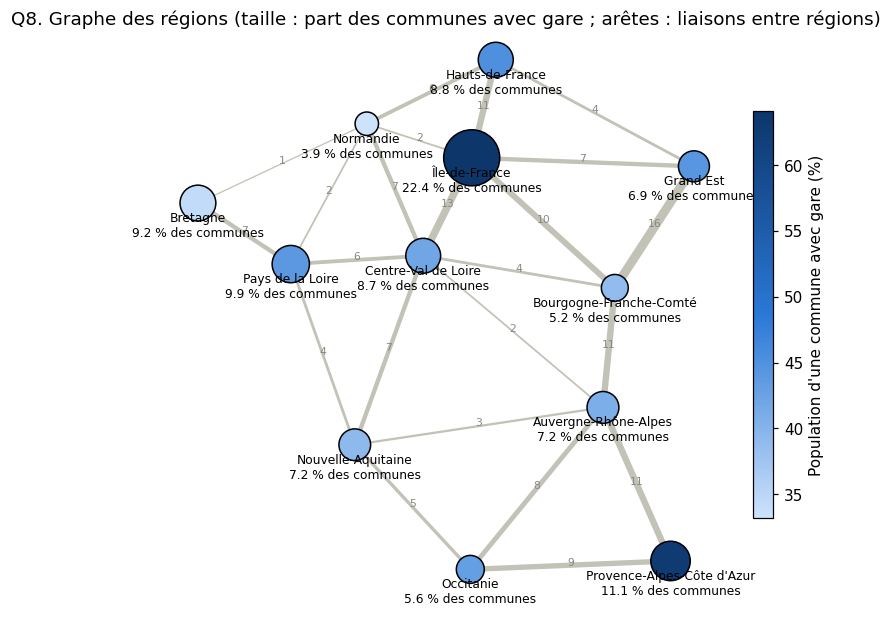

Départements où la part de population avec gare est la plus faible


,nom,communes,communes_avec_gare,part_communes_avec_gare,part_population_avec_gare
6,Ardèche,335.0,3.0,0.90,4.9
30,Gers,458.0,4.0,0.87,18.8
68,Haute-Saône,536.0,7.0,1.31,20.5
3,Alpes-de-Haute-Provence,198.0,4.0,2.02,21.9
51,Mayenne,240.0,9.0,3.75,23.1
38,Landes,327.0,15.0,4.59,23.2
41,Haute-Loire,257.0,18.0,7.00,23.2
21,Creuse,255.0,12.0,4.71,23.4


In [25]:
regions = pd.read_csv(DONNEES / "regions.csv", dtype={"code": str}).set_index("code")
departements = pd.read_csv(DONNEES / "departements.csv", dtype={"code": str})
display(regions[["nom", "communes", "communes_avec_gare", "part_communes_avec_gare", "part_population_avec_gare",
                 "villes_desservies", "villes_non_desservies"]].sort_values("part_population_avec_gare"))

# Graphe quotient : un nœud par région, une arête quand des liaisons relient deux régions (poids = nombre de liaisons)
blocs = [set(groupe.index) for _, groupe in villes.loc[list(P)].groupby("region")]
R = nx.quotient_graph(P, blocs, relabel=False)
R = nx.relabel_nodes(R, {bloc: villes.region[next(iter(bloc))] for bloc in R})
pos_region = {r: (villes.lon[villes.region == r].mean(), villes.lat[villes.region == r].mean()) for r in R}

fig, ax = plt.subplots(figsize=(8, 8))
for a, b, poids in R.edges(data="weight"):
    ax.plot(*zip(pos_region[a], pos_region[b]), color=GRIS, lw=0.5 + poids / 3, zorder=1)
    ax.annotate(poids, np.mean([pos_region[a], pos_region[b]], axis=0), fontsize=7, color="#898781", ha="center")
x, y = zip(*[pos_region[r] for r in R])
points = ax.scatter(x, y, s=[60 * regions.part_communes_avec_gare[r] for r in R],
                    c=[regions.part_population_avec_gare[r] for r in R], cmap=BLEUS, edgecolors="black", zorder=2)
plt.colorbar(points, ax=ax, shrink=0.6, label="Population d'une commune avec gare (%)")
for r in R:
    ax.annotate(f"{regions.nom[r]}\n{regions.part_communes_avec_gare[r]:.1f} % des communes", pos_region[r],
                xytext=(0, -22), textcoords="offset points", ha="center", fontsize=8)
carte(ax, "Q8. Graphe des régions (taille : part des communes avec gare ; arêtes : liaisons entre régions)")
plt.savefig(FIGURES / "Q8_regions.png", bbox_inches="tight")
plt.show()

colonnes = ["nom", "communes", "communes_avec_gare", "part_communes_avec_gare", "part_population_avec_gare"]
print("Départements où la part de population avec gare est la plus faible")
display(departements.nsmallest(8, "part_population_avec_gare")[colonnes])

**Figure 8 — Le graphe des régions.** Un nœud par région, placé au barycentre de ses villes (taille : part des communes avec gare ; couleur : part de la population vivant dans une commune avec gare) ; une arête par paire de régions reliées (nombre de liaisons).
- L'**Île-de-France** et **Provence-Alpes-Côte d'Azur** sont les mieux couvertes (environ 63 % de la population), la **Normandie** et la **Bretagne** les moins (33 et 34 %).
- La Normandie, région de Rouen, n'est reliée à l'Île-de-France que par **2 liaisons** : un goulot d'étranglement pour les trajets de la promotion. La Bretagne n'est reliée qu'aux Pays de la Loire (7) et à la Normandie (1). La paire la plus liée est Grand Est - Bourgogne-Franche-Comté (16).
- Les villes avec gare mais sans train sont surtout dans les **Hauts-de-France** et le **Grand Est**, sur d'anciennes lignes industrielles et frontalières. À l'échelle des départements, l'**Ardèche** est un cas extrême : 3 communes sur 335 ont une gare (4,9 % de la population).

In [26]:
if CYTOSCAPE:  # graphe quotient : nouveau réseau (une région = un nœud), tailles et couleurs par Continuous Mapping
    noeuds = regions.loc[list(R)].reset_index().rename(columns={"code": "id"})
    aretes = pd.DataFrame([(a, b, w) for a, b, w in R.edges(data="weight")], columns=["source", "target", "liaisons"])
    xy = pd.DataFrame(pos_region, index=["lon", "lat"]).T
    graphe_regions = cy_reseau(noeuds, aretes, "Graphe des régions", xy.lon * 100, -xy.lat * 145)
    cy_style("Q8_regions", graphe_regions, arete=2, etiquette="nom")
    p4c.set_node_size_mapping("part_communes_avec_gare", [0, regions.part_communes_avec_gare.max()], [10, 90], style_name="Q8_regions")
    p4c.set_node_color_mapping("part_population_avec_gare", [30, 65], ["#cde2fb", "#0d366b"], style_name="Q8_regions")
    p4c.set_edge_line_width_mapping("liaisons", [1, aretes.liaisons.max()], [1, 12], style_name="Q8_regions")
    p4c.set_edge_label_mapping("liaisons", style_name="Q8_regions")
    cy_figure("Q8_regions", graphe_regions)

## Q9. Quelles villes ne sont pas connectées ?

**Notion du cours** : les **composantes connexes**. Une ville peut être déconnectée :
- **dans l'infrastructure** : elle n'appartient pas à la plus grande composante connexe ;
- **dans le service** : sa gare est reliée au réseau, mais aucun train ne s'y arrête un mardi type.

Hors du réseau principal : Tremblay-En-France, Audun-le-Tiche
Villes avec gare mais sans train un mardi type : 119


,nom,departement,population,nb_gares
id,,,,
44035,La Chapelle-sur-Erdre,44,20690.0,4
30028,Bagnols-sur-Cèze,30,18112.0,1
57757,Yutz,57,17391.0,1
76447,Montivilliers,76,15478.0,2
71014,Autun,71,13172.0,1
59152,Comines,59,12731.0,2
59386,Marquette-lez-Lille,59,12622.0,1
27284,Gisors,27,12410.0,1
59636,Wambrechies,59,11012.0,1


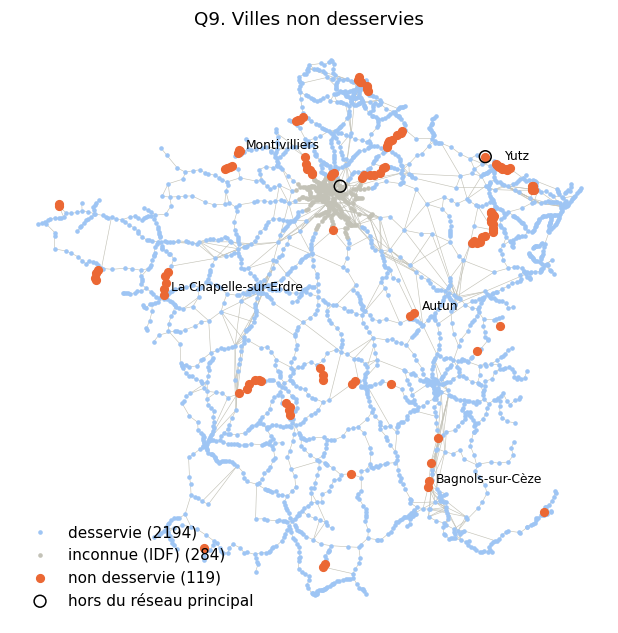

In [27]:
hors_reseau = villes[~villes.reseau_principal]
non_desservies = villes[villes.statut_desserte == "non desservie"]
print("Hors du réseau principal :", ", ".join(hors_reseau.nom))
print(f"Villes avec gare mais sans train un mardi type : {len(non_desservies)}")
display(non_desservies.nlargest(10, "population")[["nom", "departement", "population", "nb_gares"]])

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, G.edges())
for statut, couleur, taille in [("desservie", "#9ec5f4", 4), ("inconnue (IDF)", GRIS, 4), ("non desservie", ORANGE, 25)]:
    v = villes[villes.statut_desserte == statut]
    ax.scatter(v.lon, v.lat, s=taille, color=couleur, label=f"{statut} ({len(v)})", zorder=2)
ax.scatter(hors_reseau.lon, hors_reseau.lat, s=60, facecolors="none", edgecolors="black", label="hors du réseau principal", zorder=3)
nommer(ax, non_desservies.nlargest(5, "population").index)
ax.legend(frameon=False, loc="lower left")
carte(ax, "Q9. Villes non desservies")
plt.savefig(FIGURES / "Q9_non_desservies.png", bbox_inches="tight")
plt.show()

**Figure 9 — Les villes non connectées.** Orange : villes avec gare mais sans train ce mardi-là ; cercles noirs : villes hors du réseau principal ; gris : Île-de-France, où la desserte est inconnue (pas de Transilien dans les données).
- **Dans l'infrastructure**, seules 2 villes sont hors du réseau principal : Audun-le-Tiche, reliée à la France par le seul Luxembourg, et Tremblay-en-France (gare Aéroport-Charles-de-Gaulle 2 TGV), à cause d'un raccordement manquant dans le prétraitement.
- **Dans le service**, 119 villes ont une gare mais aucun train : Bagnols-sur-Cèze et Pont-Saint-Esprit (rive droite du Rhône), Yutz, Montivilliers, Autun… Certaines sont desservies par un mode absent du GTFS SNCF : le tram-train à La Chapelle-sur-Erdre, le car TER ailleurs.

In [28]:
if CYTOSCAPE:  # Style → Node → Fill Color et Size : colonne statut_desserte, Discrete Mapping
    cy_etiquettes(non_desservies.nlargest(5, "population").index)
    cy_style("Q9_desserte", BASE)
    p4c.set_node_color_mapping("statut_desserte", ["desservie", "inconnue (IDF)", "non desservie"],
                               ["#9ec5f4", GRIS, ORANGE], mapping_type="d", style_name="Q9_desserte")
    p4c.set_node_size_mapping("statut_desserte", ["desservie", "inconnue (IDF)", "non desservie"], [5, 5, 20],
                              mapping_type="d", style_name="Q9_desserte")
    cy_figure("Q9_desserte", BASE)

## Q10. Quelles gares sont les plus connectées, et les moins connectées ?

**Notion du cours** : le **degré** $k(v)$ est le nombre de voisins d'un nœud ; la **distribution des degrés** $p(k)$ caractérise la structure du réseau. Les réseaux métaboliques du cours ont quelques *super hubs* de très fort degré.

**Méthode** : le degré est mesuré sur deux graphes :
- **l'infrastructure** (graphe des villes) : nombre de villes voisines sur le rail ;
- **le réseau desservi** (`gtfs_fr_*`, une gare par nœud) : nombre de gares atteintes par un train **direct**, sans arrêt intermédiaire. Le **degré pondéré** (somme des trains par jour) mesure en plus l'intensité du service.

In [29]:
degre = pd.Series(dict(G.degree()))
print("Infrastructure, degré le plus fort :", ", ".join(f"{villes.nom[v]} ({k})" for v, k in degre.nlargest(5).items()))
print(f"Infrastructure, degré 1 (terminus) : {(degre == 1).sum()} villes ; degré 0 (isolées) : {(degre == 0).sum()}")
display(villes.loc[degre[degre == 1].index].nlargest(8, "population")[["nom", "departement", "population"]])

gares_fr = pd.read_csv(DONNEES / "gtfs_fr_nodes.csv", dtype={"id": str}).set_index("id")
dessertes = pd.read_csv(DONNEES / "gtfs_fr_edges.csv", dtype={"source": str, "target": str})
D = nx.from_pandas_edgelist(dessertes, "source", "target", edge_attr="nb_trains")
degre_d = pd.Series(dict(D.degree()))
trains_d = pd.Series(dict(D.degree(weight="nb_trains")))
display(pd.DataFrame({"gare": gares_fr.nom, "gares en direct (degré)": degre_d, "trains par jour (degré pondéré)": trains_d})
        .dropna().sort_values("gares en direct (degré)", ascending=False).head(8))

Infrastructure, degré le plus fort : Tournan-en-Brie (13), Montereau-Fault-Yonne (13), Collonges-et-Premières (13), La Houssaye-en-Brie (13), Bollène (12)
Infrastructure, degré 1 (terminus) : 66 villes ; degré 0 (isolées) : 2


,nom,departement,population
29019,Brest,29,142346.0
59599,Tourcoing,59,98772.0
59183,Dunkerque,59,86263.0
50129,Cherbourg-en-Cotentin,50,78258.0
95127,Cergy,95,70906.0
83069,Hyères,83,55858.0
85194,Les Sables-d'Olonne,85,49603.0
35288,Saint-Malo,35,47439.0


,gare,gares en direct (degré),trains par jour (degré pondéré)
87723197,Lyon Part Dieu,33,715
87212027,Strasbourg,29,726
87471003,Rennes,24,383
87396002,Le Mans,22,285
87286005,Lille Flandres,22,560
87581009,Bordeaux Saint-Jean,21,466
87141002,Nancy,20,382
87611004,Toulouse Matabiau,19,355


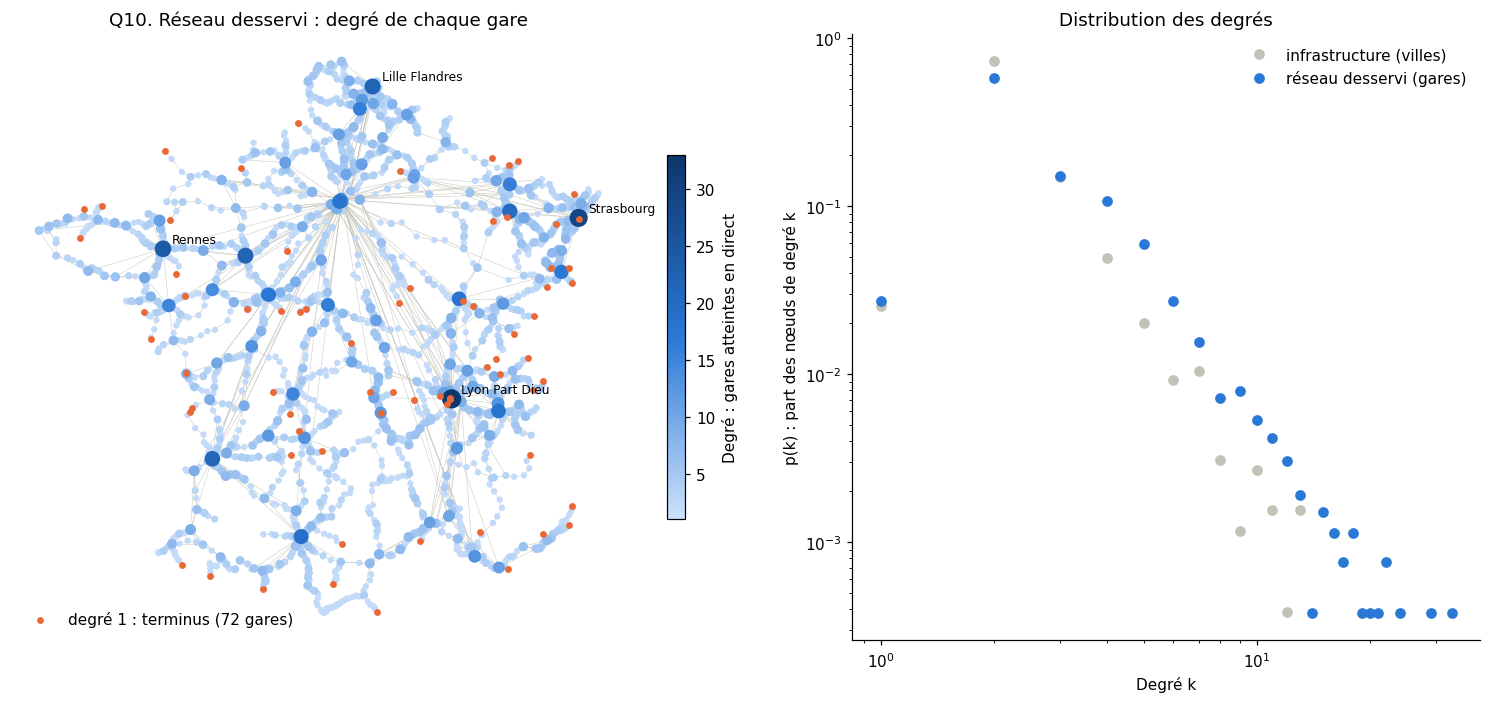

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
p = dict(zip(gares_fr.index, zip(gares_fr.lon, gares_fr.lat)))
ax.add_collection(LineCollection([(p[a], p[b]) for a, b in D.edges()], colors=GRIS, linewidths=0.3))
t = degre_d.sort_values()
points = ax.scatter(gares_fr.lon[t.index], gares_fr.lat[t.index], c=t, cmap=BLEUS, s=2 + 4 * t, zorder=2)
plt.colorbar(points, ax=ax, shrink=0.6, label="Degré : gares atteintes en direct")
un = degre_d[degre_d == 1].index
ax.scatter(gares_fr.lon[un], gares_fr.lat[un], s=12, color=ORANGE, zorder=3, label=f"degré 1 : terminus ({len(un)} gares)")
for g in degre_d.nlargest(4).index:
    ax.annotate(gares_fr.nom[g], p[g], xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.legend(frameon=False, loc="lower left")
carte(ax, "Q10. Réseau desservi : degré de chaque gare")
ax.autoscale()

ax = axes[1]
for donnees, couleur, nom in [(degre[degre > 0], GRIS, "infrastructure (villes)"), (degre_d, BLEU, "réseau desservi (gares)")]:
    pk = donnees.value_counts(normalize=True).sort_index()
    ax.loglog(pk.index, pk.values, "o", color=couleur, label=nom)
ax.set_xlabel("Degré k")
ax.set_ylabel("p(k) : part des nœuds de degré k")
ax.set_title("Distribution des degrés")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / "Q10_degre.png", bbox_inches="tight")
plt.show()

**Figure 10 — Le degré des gares.** (a) Réseau desservi : taille et couleur = nombre de gares atteintes en direct ; orange : terminus (degré 1). (b) Distribution des degrés, en échelle log-log, pour l'infrastructure (gris) et le réseau desservi (bleu).
- **Gare la plus connectée** : **Lyon Part-Dieu**, 33 gares en direct, devant Strasbourg (29) et Rennes (24) ; en trains par jour, Strasbourg passe en tête (726 contre 715). Les gares parisiennes, terminus de lignes radiales, ne desservent chacune que quelques gares en direct.
- **Dans l'infrastructure**, les plus forts degrés (13) sont des **bifurcations** (Tournan-en-Brie, Montereau-Fault-Yonne) : le degré mesure la position dans le réseau des voies, pas l'importance du service. 66 villes sont des **terminus** (Brest, Tourcoing, Dunkerque, Cherbourg…).
- **Pas de super hubs** : presque toutes les villes ont un degré 2 (milieu de ligne) et le maximum reste faible (13 ; 33 en desserte directe). Contrairement aux réseaux métaboliques, la géographie limite le nombre de voies qui partent d'une gare.

In [31]:
if CYTOSCAPE:  # Tools → Analyze Network : Cytoscape calcule lui-même la colonne Degree
    p4c.set_current_network(BASE)
    p4c.analyze_network()  # Degree, ClosenessCentrality, BetweennessCentrality, Eccentricity… ajoutés à la table
    cy_etiquettes(degre.nlargest(4).index)
    cy_style("Q10_degre", BASE)
    p4c.set_node_size_mapping("Degree", [1, degre.max()], [4, 40], style_name="Q10_degre")
    p4c.set_node_color_mapping("Degree", [1, 2, degre.max()], [ORANGE, "#cde2fb", "#0d366b"], style_name="Q10_degre")
    cy_figure("Q10_degre_infrastructure", BASE)
    # réseau desservi : un nœud par gare, une arête par paire d'arrêts consécutifs d'un train
    noeuds = gares_fr.loc[list(D)].reset_index()
    desservi_cy = cy_reseau(noeuds, dessertes, "Réseau desservi (gares)", gares_fr.lon[list(D)] * 100, -gares_fr.lat[list(D)] * 145)
    p4c.set_current_network(desservi_cy)
    p4c.analyze_network()  # Degree sur le réseau desservi
    cy_style("Q10_desservi", desservi_cy, etiquette=None)
    p4c.set_node_size_mapping("Degree", [1, degre_d.max()], [4, 50], style_name="Q10_desservi")
    p4c.set_node_color_mapping("Degree", [1, 2, degre_d.max()], [ORANGE, "#cde2fb", "#0d366b"], style_name="Q10_desservi")
    p4c.set_edge_line_width_mapping("nb_trains", [0, dessertes.nb_trains.max()], [0.3, 8], style_name="Q10_desservi")
    cy_figure("Q10_degre_desservi", desservi_cy)

## Q11. Quel trajet passe obligatoirement par le plus de gares ?

**Notion du cours** : le **plus court chemin non pondéré** compte les arêtes, et non les km. Le **diamètre non pondéré** est le plus grand nombre d'arêtes à parcourir entre deux nœuds, par le chemin le plus direct.
**Méthode** : le trajet qui réalise ce diamètre passe **obligatoirement** par le plus de gares ; on le compare au trajet le plus long en km (Q4).

Err → Brest : 90 liaisons, 89 villes intermédiaires, 1767 km
via Perpignan, Béziers, Avignon, Paris, Rennes, Brest
À comparer : le trajet le plus long en km (La Brigue → Brest) traverse 144 villes


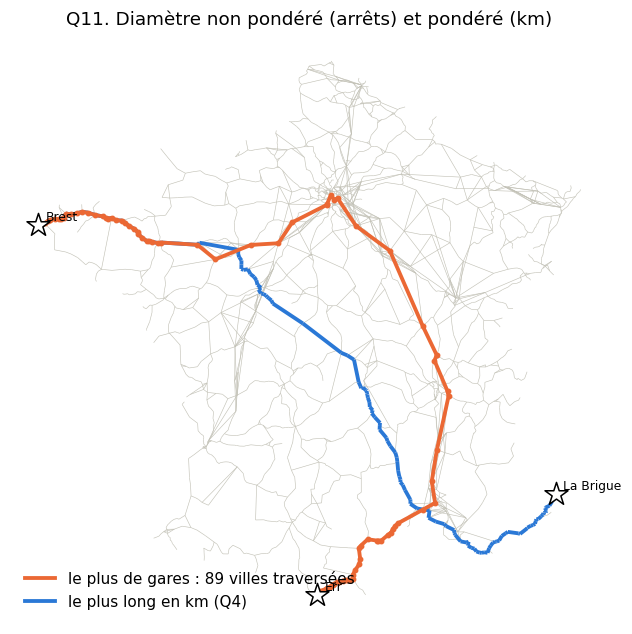

In [32]:
nb_arretes = pd.Series(nx.eccentricity(P))  # excentricité en nombre de liaisons (graphe non pondéré)
depart = nb_arretes.idxmax()
distances = nx.single_source_shortest_path_length(P, depart)
arrivee = max(distances, key=distances.get)
plus_d_arrets = nx.shortest_path(P, depart, arrivee)
print(f"{villes.nom[depart]} → {villes.nom[arrivee]} : {len(plus_d_arrets) - 1} liaisons, "
      f"{len(plus_d_arrets) - 2} villes intermédiaires, {nx.path_weight(P, plus_d_arrets, POIDS):.0f} km")
print("via", ", ".join(villes.nom[v] for v in plus_d_arrets if villes.population[v] > 80000))
print(f"À comparer : le trajet le plus long en km ({villes.nom[plus_long[0]]} → {villes.nom[plus_long[-1]]}) "
      f"traverse {len(plus_long) - 2} villes")

fig, ax = plt.subplots(figsize=(7, 7))
tracer_liaisons(ax, P.edges())
tracer_liaisons(ax, zip(plus_long, plus_long[1:]), couleur=BLEU, epaisseur=2.5)
tracer_liaisons(ax, zip(plus_d_arrets, plus_d_arrets[1:]), couleur=ORANGE, epaisseur=2.5)
ax.scatter(villes.lon[plus_d_arrets], villes.lat[plus_d_arrets], s=8, color=ORANGE, zorder=3)
nommer(ax, list(dict.fromkeys([depart, arrivee, plus_long[0], plus_long[-1]])), etoile=True)
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2.5, label=f"le plus de gares : {len(plus_d_arrets) - 2} villes traversées"),
                   Line2D([], [], color=BLEU, lw=2.5, label="le plus long en km (Q4)")], loc="lower left", frameon=False)
carte(ax, "Q11. Diamètre non pondéré (arrêts) et pondéré (km)")
plt.savefig(FIGURES / "Q11_plus_de_gares.png", bbox_inches="tight")
plt.show()

**Figure 11 — Diamètre non pondéré et pondéré.** Orange : le trajet qui passe obligatoirement par le plus de gares, d'**Err** (Cerdagne) à **Brest** : 90 liaisons, 89 villes traversées (Perpignan, Béziers, Avignon, Paris, Rennes…), 1 767 km. Bleu : le trajet le plus long en km (Brest → La Brigue, figure 4). Le chemin le plus direct en nombre d'arrêts emprunte les LGV (959 km sur 1 767), où les gares sont rares, plutôt que le Massif central, où elles sont nombreuses : plus court chemin **non pondéré** et **pondéré** ne coïncident pas.

In [33]:
if CYTOSCAPE:  # Fill Color : colonne Eccentricity calculée par Analyze Network (en nombre de liaisons, Q10)
    chemins = pd.Series("", index=liaisons.cle)
    chemins[[cle_arete(a, b) for a, b in zip(plus_long, plus_long[1:])]] = "le plus long en km"
    chemins[[cle_arete(a, b) for a, b in zip(plus_d_arrets, plus_d_arrets[1:])]] = "le plus de gares"
    cy_colonne(chemins, "chemin_q11", table="edge")
    cy_etiquettes(list(dict.fromkeys([depart, arrivee, plus_long[0], plus_long[-1]])))
    cy_style("Q11_arrets", BASE)
    p4c.set_node_color_mapping("Eccentricity", [nb_arretes.min(), nb_arretes.max()], ["#cde2fb", "#0d366b"], style_name="Q11_arrets")
    p4c.set_edge_color_mapping("chemin_q11", ["le plus de gares", "le plus long en km"], [ORANGE, BLEU], mapping_type="d", style_name="Q11_arrets")
    p4c.set_edge_line_width_mapping("chemin_q11", ["le plus de gares", "le plus long en km"], [6, 6], mapping_type="d", style_name="Q11_arrets")
    cy_figure("Q11_plus_de_gares", BASE)

## Bonus. La France est-elle plus centralisée que l'Allemagne ?

**Notion du cours** : les **métriques globales** (degré moyen, clustering, rayon, diamètre, modularité) décrivent un réseau entier et permettent de comparer deux réseaux.
**Méthode** : réseaux **desservis** des deux pays (`gtfs_fr_*`, `gtfs_de_*`), construits de la même façon (un mardi type, sans trains de banlieue). Sans tracé dans ces fichiers, le poids est la distance à vol d'oiseau entre deux arrêts consécutifs. Pour comparer deux pays de tailles différentes, la carte montre la farness divisée par la farness minimale du pays.

In [34]:
pays = {}
for nom, code in [("France", "fr"), ("Allemagne", "de")]:
    gares = pd.read_csv(DONNEES / f"gtfs_{code}_nodes.csv", dtype={"id": str}).set_index("id")
    aretes = pd.read_csv(DONNEES / f"gtfs_{code}_edges.csv", dtype={"source": str, "target": str})
    g = nx.from_pandas_edgelist(aretes, "source", "target", edge_attr="vol_oiseau_km")
    g = g.subgraph(max(nx.connected_components(g), key=len)).copy()
    gares = gares.loc[list(g)]
    gares["farness_relative"] = 1 / pd.Series(nx.closeness_centrality(g, distance="vol_oiseau_km"))
    gares["farness_relative"] /= gares["farness_relative"].min()
    gares["excentricite"] = pd.Series(nx.eccentricity(g, weight="vol_oiseau_km"))
    communautes = nx.community.louvain_communities(g, seed=1)
    pays[nom] = (g, gares, {
        "gares": g.number_of_nodes(),
        "degré moyen": round(2 * g.number_of_edges() / g.number_of_nodes(), 2),
        "clustering moyen": round(nx.average_clustering(g), 3),
        "rayon (km)": round(gares.excentricite.min()),
        "diamètre (km)": round(gares.excentricite.max()),
        "modularité": round(nx.community.modularity(g, communautes), 3),
        "points d'articulation (%)": round(100 * len(list(nx.articulation_points(g))) / g.number_of_nodes(), 1),
        "farness relative médiane": round(gares.farness_relative.median(), 2),
        "centre (excentricité minimale)": gares.nom[gares.excentricite.idxmin()],
    })
pd.DataFrame({nom: resume for nom, (_, _, resume) in pays.items()})

,France,Allemagne
gares,2641,5379
degré moyen,3.07,2.71
clustering moyen,0.259,0.168
rayon (km),668,551
diamètre (km),1313,1044
modularité,0.902,0.924
points d'articulation (%),13.4,22.8
farness relative médiane,1.35,1.33
centre (excentricité minimale),Magnette,"Erfurt, Hauptbahnhof"


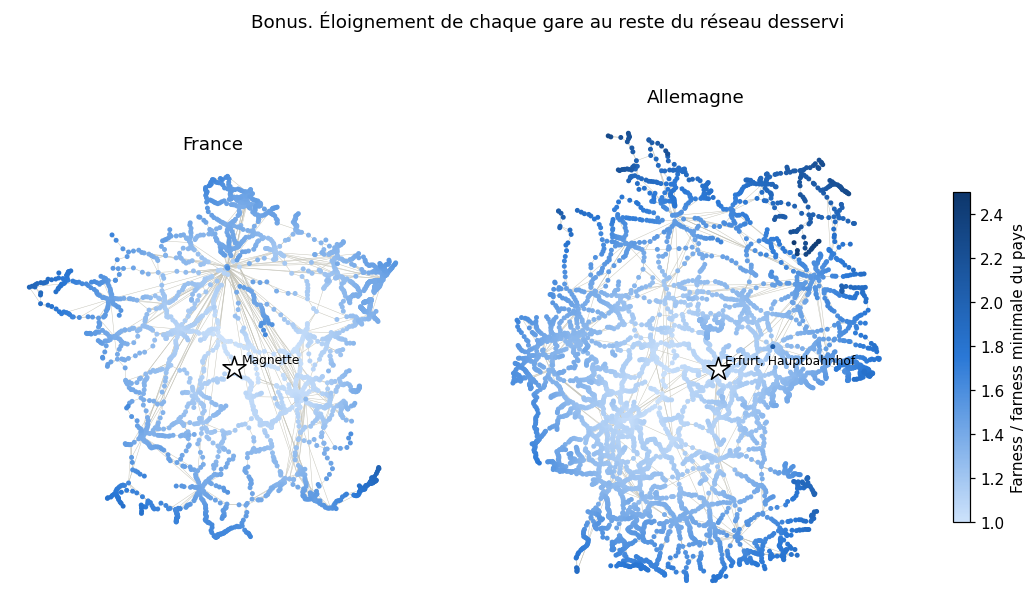

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, (nom, (g, gares, _)) in zip(axes, pays.items()):
    p = dict(zip(gares.index, zip(gares.lon, gares.lat)))
    ax.add_collection(LineCollection([(p[a], p[b]) for a, b in g.edges()], colors=GRIS, linewidths=0.3))
    t = gares.sort_values("farness_relative")
    points = ax.scatter(t.lon, t.lat, c=t.farness_relative, cmap=BLEUS, s=5, vmin=1, vmax=2.5, zorder=2)
    c = gares.excentricite.idxmin()
    ax.scatter(gares.lon[c], gares.lat[c], marker="*", s=250, c="white", edgecolors="black", zorder=3)
    ax.annotate(gares.nom[c], (gares.lon[c], gares.lat[c]), xytext=(5, 3), textcoords="offset points", fontsize=8)
    carte(ax, nom)
    ax.autoscale()
plt.colorbar(points, ax=axes, shrink=0.6, label="Farness / farness minimale du pays")
fig.suptitle("Bonus. Éloignement de chaque gare au reste du réseau desservi")
plt.savefig(FIGURES / "Bonus_France_Allemagne.png", bbox_inches="tight")
plt.show()

**Figure 12 — France et Allemagne.** Couleur : farness de chaque gare divisée par la farness minimale du pays (1 = gare la plus centrale) ; étoile : le centre (excentricité minimale), **Magnette** (Allier) en France, **Erfurt** en Allemagne, nœud des LGV Berlin-Munich et Francfort-Dresde.
- **Semblable** : la modularité (0,90 et 0,92), c'est-à-dire des réseaux régionaux bien séparés, et la farness relative médiane (1,35 et 1,33).
- **Différent** : la France est plus **radiale**, avec des liaisons directes qui partent de Paris. L'Allemagne est plus **arborescente** : 23 % de points d'articulation contre 13 %, et un clustering plus faible (0,17 contre 0,26).

In [36]:
if CYTOSCAPE:  # deux nouveaux réseaux (France, Allemagne) ; Fill Color : colonne farness_relative (Continuous)
    for nom, (g, gares, _) in pays.items():
        noeuds = gares.reset_index()[["id", "nom", "farness_relative"]]
        aretes = pd.DataFrame(list(g.edges()), columns=["source", "target"])
        reseau = cy_reseau(noeuds, aretes, f"Réseau desservi : {nom}", gares.lon * 100, -gares.lat * 145)
        cy_style(f"Bonus_{nom}", reseau, noeud=5, arete=0.5, etiquette=None)
        p4c.set_node_color_mapping("farness_relative", [1, 2.5], ["#cde2fb", "#0d366b"], style_name=f"Bonus_{nom}")
        cy_figure(f"Bonus_{nom}", reseau)

## Conclusion

- Le réseau ferré français est **radial** : LGV en étoile autour de Paris (Q1), closeness décroissante depuis l'Île-de-France (Q3), Paris en tête de la betweenness (Q5), liaisons directes plus centralisées qu'en Allemagne (bonus).
- Il est **redondant au centre et fragile en périphérie** : retirer Paris ou les 10 villes les plus centrales ne coupe presque rien, mais allonge les trajets (Q6) ; les lignes en antenne et la ligne Marseille-Vintimille sont les vrais points de coupure.
- Les **métriques ne disent pas la même chose** : centre par la moyenne (Juvisy) ou par le pire (Montluçon, Q3-Q4), plus court chemin en km ou en arrêts (Q4, Q11), degré de l'infrastructure ou du service (Q10).
- **Limites** : distances en km et non en temps, correspondances non comptées, Transilien et RER absents des horaires, et un seul jour (un mardi) observé.